# 04 · La feature y el detector

**Pregunta de este notebook.** ¿Cómo se combinan la serie RR y la EDR para detectar la apnea minuto a minuto con un único umbral? Se parte de la feature de la primera versión (F, la potencia cruzada RR–EDR), se mide qué aporta cada señal y a qué nivel (dentro de cada noche y entre noches), y con eso se arma la feature combinada **C**, que es la de la hipótesis (`docs/objetivos_hipotesis.md`):

- **(a)** dentro de cada noche, la potencia del RR en 0,017–0,05 Hz es mayor en los minutos con apnea;
- **(b)** entre noches, el nivel nocturno de la potencia de la EDR es mayor cuanto más apnea tiene la noche;
- **(c)** sumando las dos en C, un único umbral detecta los minutos con apnea.

Todo con los registros de desarrollo. La banda (0,017–0,05 Hz, ciclos de 20 a 60 s) salió del espectro con y sin apnea (`01`, verificada con más resolución en `08` §1) y la ventana (240 s) de la resolución que hace falta para verla. Se ajustan el peso de C (validación cruzada por personas) y el umbral. Test se evalúa una sola vez en `05`, con los parámetros que este notebook guarda en `docs/parametros_test.json`.

In [1]:
import json
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import detrend
from scipy.stats import rankdata, spearmanr

from src.config import SPLIT_CSV
from src.data import load_apnea_labels
from src.features.build import record_series
from src.features.coupling import welch_spectra
from src.features.lomb import lomb_psd
from src.features.windows import centered_windows
from src.qrs.rr_clean import minute_quality
from src.viz.plots import ANCHO, APNEA, COLORES_CAT, GRIS, NORMAL, label_strip, save, setup

setup()
split = pd.read_csv(SPLIT_CSV)
DEV = split[split.set == "dev"].record.tolist()
SUJETO = split.set_index("record").subject
from src.config import MIN_MINUTES_PER_CLASS
from src.features.detector import BAND as BANDA, FS_U as FSU, WINDOW_S as W
F_LOMB = np.arange(0.01, 0.0501, 0.0025)

## Cómo se evalúa: medidas, niveles de análisis y qué se ajusta

**Medidas.** Todas se calculan sobre los minutos evaluados (con etiqueta y con 20 % o menos de RR corregidos).

| Medida | Qué mide | Cómo se calcula |
|---|---|---|
| Sensibilidad | Fracción de los minutos con apnea que el detector marca | VP / (VP + FN) |
| Especificidad | Fracción de los minutos normales que el detector no marca | VN / (VN + FP) |
| Exactitud | Fracción de minutos bien clasificados | (VP + VN) / total |
| Curva ROC y AUC | Qué tan bien ordena una feature los minutos, sin fijar un umbral. El AUC es la probabilidad de que un minuto con apnea elegido al azar tenga un valor mayor que un minuto normal elegido al azar: 0,5 es azar, 1 es separación perfecta | Se mueve el umbral y se grafica la sensibilidad contra 1 − especificidad; el área bajo esa curva es igual al estadístico U de Mann–Whitney dividido por (n_apnea · n_normal) (Hanley y McNeil, 1982) |
| AUC dentro de la noche | Lo mismo, comparando solo minutos de una misma noche: no influye cuánta apnea o cuánta variabilidad tiene cada persona | AUC en cada registro con al menos 20 minutos de cada tipo; se informa la media en todo el trabajo (es lo que fija la predicción P1) |
| Índice de Youden | Criterio para elegir el umbral | J = sensibilidad + especificidad − 1; se toma el umbral que lo maximiza (sección 9) |
| ρ de Spearman | Si dos cantidades crecen juntas, sin suponer una relación lineal | Correlación de Pearson entre los rangos (Spearman, 1904) |
| Intervalo de confianza al 95 % por bootstrap de personas | Cuánto podría cambiar una medida con otras personas | Se sortean las personas con reposición (2000 a 4000 veces), se recalcula la medida con todos sus minutos y se toman los percentiles 2,5 y 97,5 (Efron y Tibshirani, 1993). Se remuestrean personas y no minutos porque los minutos de una noche no son independientes (`01`) |
| Validación cruzada por personas | El resultado con personas que no intervinieron en ningún ajuste | Las 19 personas se reparten en 5 grupos; se ajusta con 4 y se evalúa en el quinto, rotando |

**Niveles de análisis.** Cada resultado dice a qué nivel está:

| Nivel | Qué es | Dónde aparece |
|---|---|---|
| Minuto (ventana) | La decisión del detector: cada minuto, con una ventana de 240 s centrada en él | Sensibilidad, especificidad, exactitud, AUC |
| Noche (registro) | Uno de los 47 registros de desarrollo | AUC dentro de la noche; % de apnea estimado contra real; nivel nocturno de la EDR |
| Persona (sujeto) | Una de las 19 personas (puede tener varias noches) | Unidad del bootstrap y de los grupos de validación cruzada: una persona nunca está en dos grupos |
| Grupo (categoría A, B, C) | Noches agrupadas por cantidad de apnea | Descripción, por ejemplo los minutos marcados en los controles |
| Base | Todos los minutos de desarrollo juntos | AUC con todos los minutos; el umbral único |

**Qué se ajusta con los datos de desarrollo.** En test no se ajusta nada: solo se aplica lo que se fija acá.

| Qué | Cómo | ¿Usa etiquetas? | Dónde |
|---|---|---|---|
| Filtro del ECG | Especificación sacada del espectro | No | `02` |
| Mejoras del detector de latidos | Registros donde fallaba; revisión manual | No | `02` |
| Variante de EDR | Coherencia con la respiración y AUC dentro de la noche | Sí (la segunda medida) | `03` |
| Banda 0,017–0,05 Hz (k = 2…6) | Espectro con y sin apnea dentro de cada registro | Sí | `01`, `08` §1 |
| Peso w de C | Validación cruzada por personas | Sí | sección 7 |
| μ, σ y umbral | Todos los minutos de desarrollo | El umbral sí | secciones 9 y 14 |
| Cortes de la confianza | Percentiles del movimiento | No | sección 12 |

## 1. La feature

Para cada minuto se toma una ventana de 240 s centrada en él, con la serie RR y la EDR **relativa** (área del QRS dividida por el tamaño típico del QRS del registro, `03` sección 7) interpoladas a 2 Hz (`02`, `03`). En esa ventana se estima, por el método de Welch (Welch, 1967; 3 segmentos de 120 s, ventana de Hann, 50 % de solapamiento):

- el espectro del RR, S_RR(f), y el de la EDR, S_EDR(f): cuánta potencia tiene cada señal en cada frecuencia;
- el **espectro cruzado**, S_RR,EDR(f) = promedio sobre segmentos de X_RR(f)* · X_EDR(f), donde X son las transformadas de Fourier de cada segmento. Su módulo es grande en las frecuencias donde **las dos señales oscilan a la vez y con una relación de fase que se repite** de un segmento a otro; si oscilan sin relación, los productos de los segmentos tienen fases al azar y se cancelan al promediar.

**F = log₁₀ del módulo del espectro cruzado promediado en 0,017–0,05 Hz.** Se usa el logaritmo porque la potencia varía en órdenes de magnitud entre minutos y personas. Para la pregunta secundaria se calculan, con la misma ventana y la misma banda:

- **RR solo (Welch)**: log₁₀ de S_RR en la banda. Es la comparación justa con F: mismo estimador, solo falta la EDR.
- **RR solo (Lomb)**: la potencia del RR en la banda estimada con el periodograma de Lomb (Lomb, 1976) sobre los latidos, sin interpolar. Estima el espectro directamente sobre los instantes de cada latido, que no están equiespaciados (Laguna et al., 1998); el análisis espectral de la variabilidad cardíaca sigue las recomendaciones del Task Force (1996).
- **EDR sola**: log₁₀ de S_EDR en la banda.

Se evalúan los minutos con etiqueta y con 20 % o menos de RR corregidos. La tabla por minuto sale de `src/features/detector.py` (`minute_table`), el mismo código que usa test.

**La grilla de frecuencias.** Cada segmento de Welch dura 120 s, así que el espectro se obtiene en las frecuencias k/120 Hz (resolución de 0,0083 Hz). En la banda 0,01–0,05 Hz caen k = 2, …, 6: 0,017, 0,025, 0,033, 0,042 y 0,05 Hz, es decir, oscilaciones de 60, 40, 30, 24 y 20 s de período. La ventana de Hann ensancha cada frecuencia en unos ±0,008 Hz, así que en la práctica la banda cubre períodos de ~17 a ~120 s.

**Por qué interpolar, y por qué a 2 Hz.** El RR y la EDR tienen un valor por latido, en instantes que no están equiespaciados; el método de Welch (como cualquier estimador basado en la FFT) necesita muestras a intervalos regulares, así que primero hay que remuestrear la serie (Task Force, 1996). La frecuencia de la grilla se elige así:
- **Por encima de la frecuencia cardíaca**, para no perder información de ningún latido: en desarrollo la frecuencia cardíaca típica de cada noche está entre 0,8 y 1,4 Hz (mediana 1,1 Hz, con las marcas de la base). Con 2 Hz hay al menos una muestra por latido.
- **Con el límite de Nyquist (1 Hz) muy por encima de lo que interesa**: la banda de la apnea llega a 0,05 Hz y la respiración, que se usa para validar la EDR en `03`, a ~0,5 Hz (30 respiraciones por minuto).
- **Más alto no agrega nada**: las muestras de más serían interpolación pura y solo harían más lento el cálculo.

Se usa un **spline cúbico** porque da una curva suave, con derivada continua; la interpolación lineal deja "esquinas" en cada latido, que agregan potencia espuria en frecuencias altas. La sección 15 muestra que para la banda de la apnea las dos dan lo mismo.

**Qué se clasifica.** La unidad de decisión es **el minuto**, porque las etiquetas de la base son por minuto. La ventana de 240 s no es otro segmento: es el contexto que hace falta alrededor de cada minuto para estimar un espectro que llegue a 0,017 Hz (períodos de hasta 60 s, con dos ciclos completos en cada segmento de 120 s). Los ciclos de 60 a 100 s entran solo en parte (`08` §1). La ventana de 240 s es la misma en todo el trabajo (`01` sección 7, `03` medida B, este notebook); las otras duraciones que aparecen son de otra naturaleza (el largo de un latido, el ancho de un QRS) y están listadas en `docs/decisiones.md`.

In [2]:
from src.features.detector import minute_table

def features_registro(rec):
    t_ = minute_table(rec, lomb=True)
    return t_.assign(**{"RR (Welch)": t_.P_RR, "RR (Lomb)": t_.P_RR_lomb, "EDR": t_.P_EDR})

with ProcessPoolExecutor(4) as ex:
    tab = pd.concat(list(ex.map(features_registro, DEV)), ignore_index=True)
FEATS = ["F", "RR (Welch)", "RR (Lomb)", "EDR"]
ev = tab[(tab.label >= 0) & (tab.q <= 0.2)].dropna().reset_index(drop=True)
ev["subject"] = ev.record.map(SUJETO)
print(f"{len(ev)} minutos de evaluación en {ev.record.nunique()} registros ({ev.subject.nunique()} personas); "
      f"{100 * ev.label.mean():.1f} % con apnea; quedan afuera {len(tab) - len(ev)} minutos sin etiqueta o con > 20 % de RR corregidos")

22772 minutos de evaluación en 47 registros (19 personas); 40.2 % con apnea; quedan afuera 135 minutos sin etiqueta o con > 20 % de RR corregidos


## 2. Cómo se ve en una noche

Antes de medir, se mira la feature a lo largo de una noche con apnea y tramos normales (`a03`).

PosixPath('/home/user/TP-PSB-G8/informe/figuras/04_noche_a03.png')

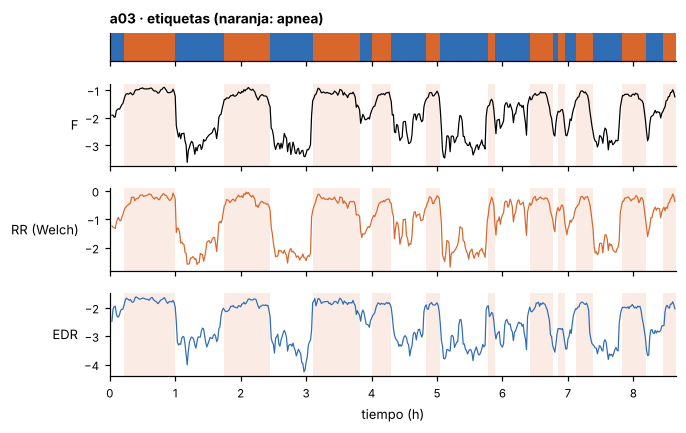

In [3]:
g = tab[tab.record == "a03"].set_index("minute")
lab03 = load_apnea_labels("a03")
fig, axs = plt.subplots(4, 1, figsize=(ANCHO, 4.0), sharex=True, gridspec_kw={"height_ratios": [0.35, 1, 1, 1]})
label_strip(axs[0], lab03, unit=60); axs[0].set_title("a03 · etiquetas (naranja: apnea)")
for ax, col, color in ((axs[1], "F", "black"), (axs[2], "RR (Welch)", APNEA), (axs[3], "EDR", NORMAL)):
    ax.plot(g.index / 60, g[col], color=color, lw=0.8)
    ax.set_ylabel(col, rotation=0, ha="right", va="center")
    for a_, b_ in zip(*[np.flatnonzero(np.diff(np.r_[0, (lab03 == 1).astype(int), 0]))[k::2] for k in (0, 1)]):
        ax.axvspan(a_ / 60, b_ / 60, color=APNEA, alpha=0.12, lw=0)
axs[-1].set_xlabel("tiempo (h)")
fig.tight_layout()
save(fig, "04_noche_a03")

**Qué se ve.** En los tramos con apnea (sombreados) F sube y se mantiene alta; en los tramos normales baja. El RR y la EDR por separado muestran el mismo patrón, con más variación dentro de cada tramo.

## 3. Dentro de cada noche

En los 31 registros de desarrollo con al menos 20 minutos de cada tipo se calcula el **AUC dentro de la noche**: la probabilidad de que un minuto con apnea elegido al azar tenga un valor mayor que un minuto normal elegido al azar **de la misma noche** (0,5 es azar, 1 es separación perfecta). Así no influye que una persona tenga más variabilidad o más apnea que otra.

,AUC dentro de la noche (media),"registros con AUC > 0,5",F − esta (media),IC 95 %,registros donde gana F
feature,,,,,
F,0.879,31/31,NaN,NaN,NaN
RR (Welch),0.908,31/31,-0.029,-0.043 a -0.009,5/31
RR (Lomb),0.891,30/31,-0.012,-0.027 a +0.010,10/31
EDR,0.803,31/31,0.075,+0.041 a +0.109,29/31


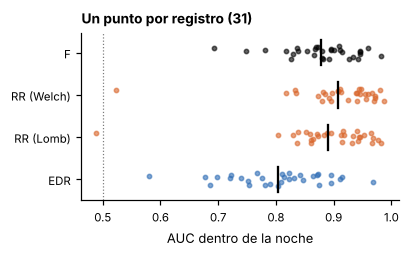

In [4]:
def auc(x, y):
    r = rankdata(x); n1 = int(y.sum()); n0 = len(y) - n1
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

dentro = []
for rec, gr in ev.groupby("record"):
    y = gr.label.to_numpy()
    if min((y == 1).sum(), (y == 0).sum()) >= MIN_MINUTES_PER_CLASS:
        dentro.append({"record": rec, "subject": SUJETO[rec], **{f_: auc(gr[f_].to_numpy(), y) for f_ in FEATS}})
dentro = pd.DataFrame(dentro)

rng = np.random.default_rng(2026)
def ic_pareado(d, suj, n=4000):
    us = np.unique(suj)
    boot = [np.mean(np.concatenate([d[suj == u] for u in rng.choice(us, len(us))])) for _ in range(n)]
    return np.percentile(boot, [2.5, 97.5])

filas = []
for f_ in FEATS:
    v = dentro[f_].to_numpy()
    fila = {"feature": f_, "AUC dentro de la noche (media)": np.mean(v),
            "registros con AUC > 0,5": f"{int((v > 0.5).sum())}/{len(v)}"}
    if f_ != "F":
        d = dentro["F"].to_numpy() - v
        lo, hi = ic_pareado(d, dentro.subject.to_numpy())
        fila.update({"F − esta (media)": d.mean(), "IC 95 %": f"{lo:+.3f} a {hi:+.3f}", "registros donde gana F": f"{int((d > 0).sum())}/{len(d)}"})
    filas.append(fila)
tabla_dentro = pd.DataFrame(filas).set_index("feature")

fig, ax = plt.subplots(figsize=(ANCHO * 0.6, 2.4))
for y_, f_ in enumerate(FEATS[::-1]):
    v = dentro[f_]
    ax.scatter(v, np.full(len(v), y_) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), s=8,
               color="black" if f_ == "F" else (APNEA if f_.startswith("RR") else NORMAL), alpha=0.6)
    ax.plot([v.mean()] * 2, [y_ - 0.3, y_ + 0.3], color="black", lw=1.5)
ax.axvline(0.5, color=GRIS, ls=":", lw=0.8)
ax.set_yticks(range(len(FEATS))); ax.set_yticklabels(FEATS[::-1])
ax.set(xlabel="AUC dentro de la noche", title="Un punto por registro (31)")
fig.tight_layout()
save(fig, "04_auc_dentro")
tabla_dentro.round(3)

**Qué se ve.**
- Las cuatro features son mayores en los minutos con apnea en casi todos los registros (AUC dentro de la noche > 0,5).
- Pero **dentro de una noche, el RR solo separa mejor que F**: la diferencia es negativa y su intervalo no incluye el cero. Sumar la EDR, que es más ruidosa, le resta al RR cuando se comparan minutos de una misma persona.

## 4. Un umbral para todos

El detector usa **un único umbral** para todas las personas, así que importa cómo separa los minutos de todos los registros juntos. La curva ROC muestra, para cada umbral posible, la sensibilidad (fracción de minutos con apnea detectados) contra 1 − especificidad (fracción de minutos normales marcados como apnea). El AUC es el área bajo esa curva. El intervalo de confianza se calcula remuestreando **personas** (2000 veces), porque los minutos de una misma noche no son independientes (`01`).

F − RR (Welch), todos los minutos: +0.092 (IC 95 % +0.017 a +0.180)


,AUC (todos los minutos),IC 95 %
feature,,
F,0.907,0.870 a 0.936
RR (Welch),0.815,0.712 a 0.906
RR (Lomb),0.793,0.686 a 0.885
EDR,0.867,0.822 a 0.905


Corrección de Holm sobre las 4 comparaciones de F (secciones 3 y 4):


,diferencia,p,p de Holm,significativa sin corregir,resiste Holm
comparación,,,,,
"F − EDR, dentro de la noche",0.0752,0.0000,0.0000,sí,sí
"F − RR (Welch), dentro de la noche",-0.0293,0.0055,0.0165,sí,sí
"F − RR (Welch), todos los minutos",0.0917,0.0080,0.0165,sí,sí
"F − RR (Lomb), dentro de la noche",-0.0120,0.2450,0.2450,no,no


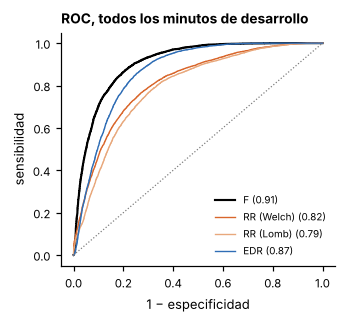

In [5]:
def roc(x, y):
    o = np.argsort(-x); y_ = y[o]
    tpr = np.r_[0, np.cumsum(y_) / y_.sum()]; fpr = np.r_[0, np.cumsum(1 - y_) / (1 - y_).sum()]
    return fpr, tpr

subj = ev.subject.to_numpy(); us = np.unique(subj)
idx_por_suj = {u: np.flatnonzero(subj == u) for u in us}
boot_idx = [np.concatenate([idx_por_suj[u] for u in rng.choice(us, len(us))]) for _ in range(2000)]
y_all = ev.label.to_numpy()
filas = []
fig, ax = plt.subplots(figsize=(3.2, 3.0))
for f_, color in zip(FEATS, ["black", APNEA, "#E8A87C", NORMAL]):
    x_all = ev[f_].to_numpy()
    a_ = auc(x_all, y_all)
    bs = np.array([auc(x_all[i], y_all[i]) for i in boot_idx])
    filas.append({"feature": f_, "AUC (todos los minutos)": a_, "IC 95 %": f"{np.percentile(bs, 2.5):.3f} a {np.percentile(bs, 97.5):.3f}"})
    fpr, tpr = roc(x_all, y_all)
    ax.plot(fpr, tpr, color=color, lw=1.4 if f_ == "F" else 0.9, label=f"{f_} ({a_:.2f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="1 − especificidad", ylabel="sensibilidad", title="ROC, todos los minutos de desarrollo")
ax.legend(loc="lower right", fontsize=6.5)
fig.tight_layout()
save(fig, "04_roc")
d_pool = np.array([auc(ev["F"].to_numpy()[i], y_all[i]) - auc(ev["RR (Welch)"].to_numpy()[i], y_all[i]) for i in boot_idx[:1000]])
print(f"F − RR (Welch), todos los minutos: {auc(ev['F'].to_numpy(), y_all) - auc(ev['RR (Welch)'].to_numpy(), y_all):+.3f} "
      f"(IC 95 % {np.percentile(d_pool, 2.5):+.3f} a {np.percentile(d_pool, 97.5):+.3f})")
display(pd.DataFrame(filas).set_index("feature").round(3))

from src.estadistica import tabla_holm
rng_h = np.random.default_rng(2027)
suj_d = dentro.subject.to_numpy(); us_d = np.unique(suj_d)
sorteos_d = [rng_h.choice(us_d, len(us_d)) for _ in range(4000)]
fam_f = {}
for f_ in ("RR (Welch)", "RR (Lomb)", "EDR"):
    d_ = dentro["F"].to_numpy() - dentro[f_].to_numpy()
    fam_f[f"F − {f_}, dentro de la noche"] = (d_.mean(), np.array([np.mean(np.concatenate([d_[suj_d == u] for u in so])) for so in sorteos_d]))
fam_f["F − RR (Welch), todos los minutos"] = (auc(ev["F"].to_numpy(), y_all) - auc(ev["RR (Welch)"].to_numpy(), y_all), d_pool)
print("Corrección de Holm sobre las 4 comparaciones de F (secciones 3 y 4):")
tabla_holm(fam_f).round(4)

**Qué se ve.** Con todos los minutos juntos F separa bien (AUC claramente por encima de 0,5). Y acá el orden se invierte: **F supera al RR solo** (+0,09 de AUC, con un intervalo que no incluye el cero; se imprime arriba).

## 5. Por qué el resultado depende del nivel de análisis

Dentro de una noche gana el RR; con todas las noches juntas F queda arriba. La diferencia tiene que venir de algo que cambia **entre personas**. Para verlo se compara, en cada registro, el valor medio de cada feature con su fracción de minutos con apnea, primero con todos los minutos y después solo con los **minutos normales**.

,todos los minutos,solo minutos normales
F,0.85,0.47
RR (Welch),0.31,-0.35
RR (Lomb),0.27,-0.33
EDR,0.80,0.61


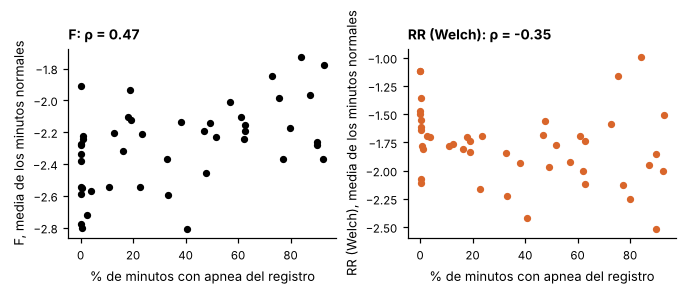

In [6]:
por_reg = ev.groupby("record").agg(frac=("label", "mean"), **{f_: (f_, "mean") for f_ in FEATS})
normales = ev[ev.label == 0].groupby("record").agg(n=("label", "size"), **{f_: (f_, "mean") for f_ in FEATS})
normales = normales[normales.n >= MIN_MINUTES_PER_CLASS].join(por_reg.frac)
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6), sharey=False)
for ax, f_, color in ((axs[0], "F", "black"), (axs[1], "RR (Welch)", APNEA)):
    ax.scatter(100 * normales.frac, normales[f_], s=14, color=color)
    rho = spearmanr(normales[f_], normales.frac)[0]
    ax.set(xlabel="% de minutos con apnea del registro", ylabel=f"{f_}, media de los minutos normales",
           title=f"{f_}: ρ = {rho:.2f}")
fig.tight_layout()
save(fig, "04_nivel_persona")
pd.DataFrame({"todos los minutos": {f_: spearmanr(por_reg[f_], por_reg.frac)[0] for f_ in FEATS},
              "solo minutos normales": {f_: spearmanr(normales[f_], normales.frac)[0] for f_ in FEATS}}).round(2)

**Qué se ve.** En las personas con más apnea, **F es más alta incluso en sus minutos normales**; el RR no (incluso tiende a lo contrario). La EDR lleva un nivel propio de cada persona que acompaña a la cantidad de apnea. Con un umbral único eso ayuda: F no solo marca los minutos con apnea, también distingue a las personas que tienen mucha. Dentro de una noche, en cambio, ese nivel es constante y no ayuda.

**Respuesta a la pregunta secundaria:** la EDR aporta información **a nivel de persona** (entre noches), pero no para distinguir un minuto de otro dentro de la misma noche, donde el RR solo es mejor.

**Una advertencia.** No se sabe qué es ese nivel personal: puede ser fisiológico (respiración más irregular durante todo el sueño, eventos más leves que no llegan a marcarse como apnea en los minutos "normales"), o depender de la anatomía y de la posición de los electrodos. Si depende de rasgos de la persona, puede generalizar peor a gente distinta; test quedó con un IMC mayor que desarrollo (`01`). Se discute como limitación.

## 6. Qué mide bien cada señal

Los resultados anteriores sugieren tres cosas, que acá se muestran con los registros de desarrollo:

1. **El RR es el que mejor marca *cuándo* hay apnea dentro de una noche, pero su nivel general cambia mucho de una persona a otra y no acompaña a la cantidad de apnea.**
2. **La EDR separa peor los minutos dentro de la noche, pero su nivel a lo largo de la noche sí acompaña a la cantidad de apnea de la persona.**
3. **F suma las dos señales minuto a minuto, así que dentro de la noche hereda lo peor de la EDR.**

### 6.1 El RR marca cuándo

Para cada registro con los dos tipos de minuto, el AUC dentro de la noche del RR contra el de la EDR, y una noche de ejemplo.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/04_rr_marca_cuando.png')

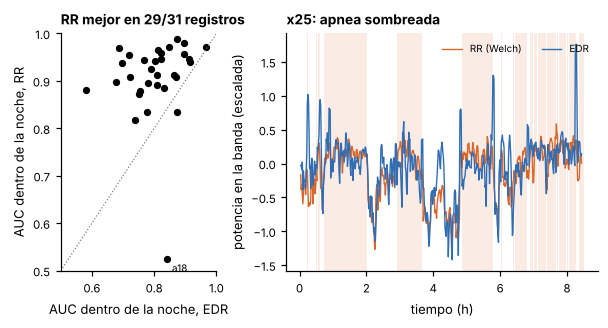

In [7]:
from src.data import load_record_info
ej = dentro.assign(dif=dentro["RR (Welch)"] - dentro["EDR"]).sort_values("dif").record.iloc[-3]   # un registro donde el RR gana claro
g_ej = tab[tab.record == ej].set_index("minute"); lab_ej = load_apnea_labels(ej)
fig = plt.figure(figsize=(ANCHO, 2.8))
gs6 = fig.add_gridspec(1, 2, width_ratios=[1, 2], wspace=0.3)
ax = fig.add_subplot(gs6[0])
ax.scatter(dentro["EDR"], dentro["RR (Welch)"], s=14, color="black")
ax.plot([0.5, 1], [0.5, 1], color=GRIS, ls=":", lw=0.8)
ax.set(xlim=(0.5, 1), ylim=(0.5, 1), xlabel="AUC dentro de la noche, EDR", ylabel="AUC dentro de la noche, RR",
       title=f"RR mejor en {int((dentro['RR (Welch)'] > dentro['EDR']).sum())}/{len(dentro)} registros")
ax.annotate("a18", (dentro.set_index("record").loc["a18", "EDR"], dentro.set_index("record").loc["a18", "RR (Welch)"]),
            fontsize=6.5, xytext=(3, -8), textcoords="offset points")
ax2 = fig.add_subplot(gs6[1])
for col, color in (("RR (Welch)", APNEA), ("EDR", NORMAL)):
    v = g_ej[col]; ax2.plot(g_ej.index / 60, (v - v.median()) / (v.quantile(0.9) - v.quantile(0.1)), color=color, lw=0.9, label=col)
bordes = np.flatnonzero(np.diff(np.r_[0, (lab_ej == 1).astype(int), 0]))
for a_, b_ in zip(bordes[::2], bordes[1::2]):
    ax2.axvspan(a_ / 60, b_ / 60, color=APNEA, alpha=0.12, lw=0)
ax2.set(xlabel="tiempo (h)", ylabel="potencia en la banda (escalada)", title=f"{ej}: apnea sombreada")
ax2.legend(loc="upper right", fontsize=6.5, ncol=2)
save(fig, "04_rr_marca_cuando")

**Qué se ve.** Casi todos los puntos quedan arriba de la diagonal: dentro de una noche el RR separa los minutos con apnea mejor que la EDR. En el ejemplo, la potencia del RR sube en cada tramo con apnea y baja en los normales; la de la EDR sigue el mismo patrón pero con más picos fuera de los tramos de apnea. La excepción es `a18`, donde el RR casi no cambia con la apnea y la EDR sí.

### 6.2 El nivel de cada señal a lo largo de la noche

Ahora la otra escala: cuánto vale cada señal en cada persona. Cada columna es un registro, ordenados por su fracción de minutos con apnea; las cajas muestran la potencia en la banda de sus minutos normales (azul) y con apnea (naranja).

,mediana de la noche vs % de apnea,minutos normales vs % de apnea,minutos normales vs edad,minutos normales vs IMC
RR (Welch),0.42,-0.35,-0.11,-0.37
EDR,0.83,0.61,0.39,0.48


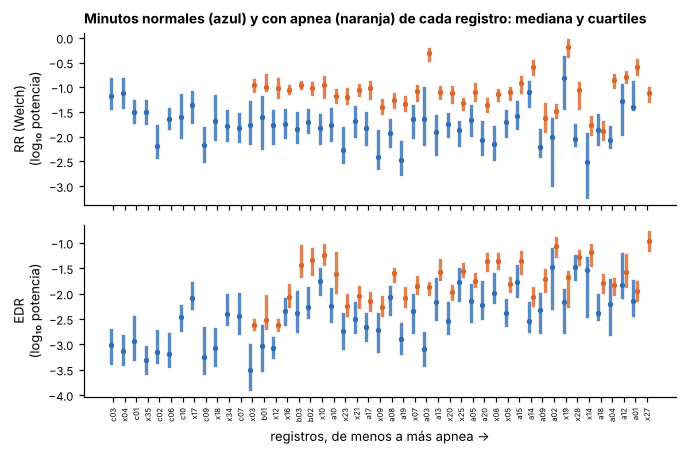

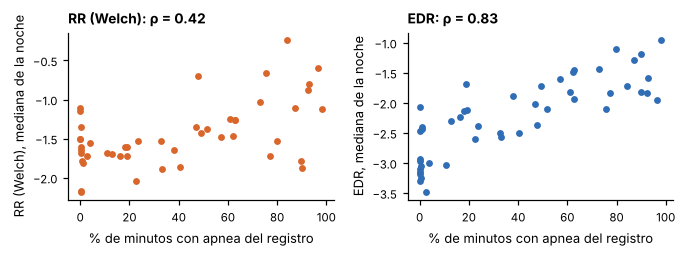

In [8]:
orden_r = ev.groupby("record").label.mean().sort_values().index
fig, axs = plt.subplots(2, 1, figsize=(ANCHO, 4.2), sharex=True)
for ax, col in zip(axs, ["RR (Welch)", "EDR"]):
    for i, rec_ in enumerate(orden_r):
        g_ = ev[ev.record == rec_]
        for lab_, color, dx in ((0, NORMAL, -0.18), (1, APNEA, 0.18)):
            v = g_.loc[g_.label == lab_, col]
            if len(v) >= 10:
                q1, q2, q3 = v.quantile([0.25, 0.5, 0.75])
                ax.plot([i + dx] * 2, [q1, q3], color=color, lw=2.2, alpha=0.8)
                ax.plot(i + dx, q2, "o", color=color, ms=2.5)
    ax.set(ylabel=f"{col}\n(log₁₀ potencia)")
axs[0].set_title("Minutos normales (azul) y con apnea (naranja) de cada registro: mediana y cuartiles")
axs[1].set_xticks(range(len(orden_r))); axs[1].set_xticklabels(orden_r, rotation=90, fontsize=5)
axs[1].set_xlabel("registros, de menos a más apnea →")
fig.tight_layout()
save(fig, "04_nivel_por_registro")

med_noche = tab.groupby("record")[["RR (Welch)", "EDR"]].median()        # todos los minutos, sin etiquetas
frac_r = ev.groupby("record").label.mean()
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.4))
for ax, col, color in ((axs[0], "RR (Welch)", APNEA), (axs[1], "EDR", NORMAL)):
    rho = spearmanr(med_noche.loc[frac_r.index, col], frac_r)[0]
    ax.scatter(100 * frac_r, med_noche.loc[frac_r.index, col], s=12, color=color)
    ax.set(xlabel="% de minutos con apnea del registro", ylabel=f"{col}, mediana de la noche", title=f"{col}: ρ = {rho:.2f}")
fig.tight_layout()
save(fig, "04_nivel_noche")
info_r = load_record_info().set_index("record")
imc = info_r.weight_kg / (info_r.height_cm / 100) ** 2
pd.DataFrame({
    "mediana de la noche vs % de apnea": {c: spearmanr(med_noche.loc[frac_r.index, c], frac_r)[0] for c in ["RR (Welch)", "EDR"]},
    "minutos normales vs % de apnea": {c: spearmanr(normales[c], normales.frac)[0] for c in ["RR (Welch)", "EDR"]},
    "minutos normales vs edad": {c: spearmanr(normales[c], info_r.age[normales.index])[0] for c in ["RR (Welch)", "EDR"]},
    "minutos normales vs IMC": {c: spearmanr(normales[c], imc[normales.index])[0] for c in ["RR (Welch)", "EDR"]},
}).round(2)

**Qué se ve.**
- **RR (arriba)**: dentro de cada registro la caja naranja queda arriba de la azul (marca la apnea), pero el nivel general salta mucho de un registro a otro: los minutos normales de algunas personas tienen más potencia que los minutos con apnea de otras. Ese nivel no acompaña a la cantidad de apnea (la mediana de la noche apenas se relaciona con el % de apnea).
- **EDR (abajo)**: dentro de cada registro las cajas se superponen más (separa peor los minutos), pero el nivel general **sube de izquierda a derecha**: las personas con más apnea tienen más potencia lenta en la EDR, incluso en sus minutos normales. La mediana de la noche de la EDR acompaña bien al % de apnea.
- **Una advertencia**: en desarrollo, las personas con más apnea son también mayores y con más IMC, y el nivel de la EDR en los minutos normales también acompaña a la edad y al IMC (tabla). No se puede separar si la EDR refleja la apnea o el tipo de persona que la tiene. Test quedó con un IMC mayor (`01`), así que es algo a mirar al interpretarlo.

### 6.3 F hereda la EDR dentro de la noche

F es el logaritmo de la potencia cruzada. Si las dos señales oscilan juntas, el espectro cruzado vale aproximadamente la raíz del producto de los dos espectros, así que F queda cerca del **promedio** de los logaritmos de las potencias del RR y de la EDR.

PosixPath('/home/user/TP-PSB-G8/informe/figuras/04_f_hereda.png')

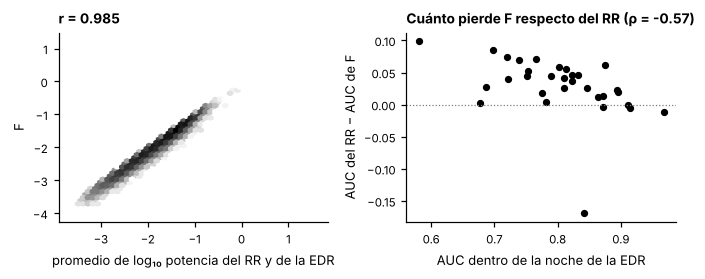

In [9]:
prom = (ev["RR (Welch)"] + ev["EDR"]) / 2
dentro_ = dentro.set_index("record")
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
axs[0].hexbin(prom, ev["F"], gridsize=50, cmap="Greys", mincnt=1, bins="log")
axs[0].set(xlabel="promedio de log₁₀ potencia del RR y de la EDR", ylabel="F", title=f"r = {np.corrcoef(prom, ev['F'])[0, 1]:.3f}")
axs[1].scatter(dentro_["EDR"], dentro_["RR (Welch)"] - dentro_["F"], s=14, color="black")
axs[1].axhline(0, color=GRIS, ls=":", lw=0.8)
rho_h = spearmanr(dentro_["EDR"], dentro_["RR (Welch)"] - dentro_["F"])[0]
axs[1].set(xlabel="AUC dentro de la noche de la EDR", ylabel="AUC del RR − AUC de F", title=f"Cuánto pierde F respecto del RR (ρ = {rho_h:.2f})")
fig.tight_layout()
save(fig, "04_f_hereda")

**Qué se ve.** F y el promedio de las dos potencias son casi la misma cosa (r cercano a 1): F funciona sobre todo porque **suma** la información de las dos señales; que oscilen sincronizadas agrega poco. A la derecha: cuanto peor separa la EDR en un registro, más pierde F respecto del RR solo. Dentro de la noche, sumar la EDR minuto a minuto le agrega al RR el ruido de la EDR.

**Resumen de la sección.** El RR sirve para ubicar la apnea dentro de la noche; la EDR, para saber cuánta apnea tiene la persona. F usa las dos, pero las mezcla minuto a minuto y dentro de la noche queda peor que el RR solo.

## 7. La feature combinada C

Con lo que mide bien cada señal, la combinación natural es: **el RR de cada minuto para ubicar la apnea, y el nivel nocturno de la EDR para corregir cuánta apnea tiene cada noche**:

**C(m) = [P_RR(m) − μ₁] / σ₁ + w · [P̄_EDR − μ₂] / σ₂**

- **P_RR(m)**: la potencia del RR en la banda en el minuto m (sección 1). Cambia de un minuto a otro.
- **P̄_EDR**: la mediana de la potencia de la EDR en todos los minutos de la noche. Es **el mismo número para toda la noche** y no usa etiquetas.
- **μ y σ**: media y desvío de cada término en los minutos de desarrollo. Son números fijos, iguales para todos (no es una normalización por persona): un cambio de unidades para que el peso w compare los dos términos en la misma escala.
- **w**: cuánto pesa el término de la EDR. Se elige por validación cruzada (abajo).

Un minuto es apnea si C supera un umbral u. Como el término de la EDR (llamémoslo B) es constante en la noche, la regla C > u equivale a **[P_RR(m) − μ₁]/σ₁ > u − B**: el RR tiene que superar un valor que depende de la noche. **Dentro de una noche, C ordena los minutos exactamente igual que el RR** (su AUC dentro de la noche es el del RR); entre noches, el nivel de la EDR corre ese valor.

**¿Hace falta sacar el nivel del RR de cada persona?** El nivel del RR cambia entre personas sin relación con la apnea (sección 6.2), así que se probó también la variante **G**, que le resta al RR la mediana de su noche. El nivel nocturno del RR tiene dos componentes que van en sentidos opuestos (tabla de 6.2): la composición de la noche (más minutos con apnea suben la mediana: ρ = +0,42 con el % de apnea) y el nivel propio de la persona (en los minutos normales, ρ = −0,35). Restar la mediana saca las dos. Se comparan C y G con el mismo procedimiento.

**Validación cruzada por personas.** Las 19 personas de desarrollo se reparten en 5 grupos. Para cada grupo, con las otras 4: se estandarizan los términos, se elige el peso w (de 0 a 3, cada 0,25) que maximiza el AUC con todos los minutos y se fija el umbral de Youden; después se clasifica el grupo que quedó afuera. Así cada minuto se clasifica con un detector que no vio a su persona.

peso elegido con todo desarrollo: w = 1


,pesos elegidos en los 5 grupos,sensibilidad,especificidad,exactitud,AUC (personas no vistas),AUC dentro de la noche,ρ por noche,% marcado en controles
detector,,,,,,,,
C (RR + nivel EDR),"1.5, 0.75, 1, 1.25, 1",0.814,0.851,0.836,0.907,0.908,0.795,7.376
G (RR centrado + nivel EDR),"1.75, 1.5, 1.5, 1.5, 1.5",0.895,0.785,0.829,0.914,0.908,0.859,11.914
F (primera versión),,0.860,0.793,0.820,0.903,0.879,0.866,16.740
RR solo,,0.748,0.734,0.740,0.824,0.908,0.359,36.860


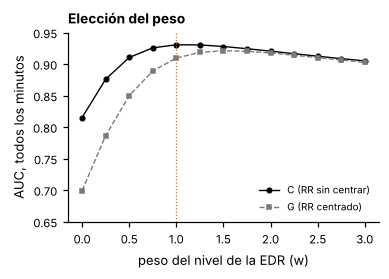

In [10]:
from src.features.detector import c_score, confidence, fit_c, save_params, youden_threshold

GRILLA_W = np.arange(0, 3.01, 0.25)
grupos = np.array_split(np.random.default_rng(2026).permutation(us), 5)

def metricas(y, pred):
    tp = int(((pred == 1) & (y == 1)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    return {"sensibilidad": tp / (y == 1).sum(), "especificidad": tn / (y == 0).sum(), "exactitud": (tp + tn) / len(y)}

def cv_variante(rr_col):
    """Validación cruzada por personas de la suma RR + w·EDR_noche (rr_col: P_RR para C, RR_dev para G)."""
    pred = np.zeros(len(ev), int); pesos, aucs = [], []; marg = np.zeros(len(ev))
    for gpo in grupos:
        te = np.isin(subj, gpo); tr = ~te
        a_w = [auc(c_score(ev[tr], fit_c(ev[tr], w, rr_col)).to_numpy(), y_all[tr]) for w in GRILLA_W]
        w_ = float(GRILLA_W[int(np.argmax(a_w))]); pesos.append(w_)
        p_ = fit_c(ev[tr], w_, rr_col)
        u_ = youden_threshold(c_score(ev[tr], p_).to_numpy(), y_all[tr])
        s_te = c_score(ev[te], p_).to_numpy(); pred[te] = (s_te > u_); aucs.append(auc(s_te, y_all[te])); marg[te] = s_te - u_
    return pred, pesos, float(np.mean(aucs)), marg

def cv_simple(col):
    pred = np.zeros(len(ev), int); aucs = []
    for gpo in grupos:
        te = np.isin(subj, gpo); tr = ~te
        u_ = youden_threshold(ev[col].to_numpy()[tr], y_all[tr])
        pred[te] = ev[col].to_numpy()[te] > u_; aucs.append(auc(ev[col].to_numpy()[te], y_all[te]))
    return pred, None, float(np.mean(aucs)), None

resultados = {"C (RR + nivel EDR)": cv_variante("P_RR"), "G (RR centrado + nivel EDR)": cv_variante("RR_dev"),
              "F (primera versión)": cv_simple("F"), "RR solo": cv_simple("RR (Welch)")}
auc_dentro = {"C (RR + nivel EDR)": dentro["RR (Welch)"].mean(), "G (RR centrado + nivel EDR)": dentro["RR (Welch)"].mean(),
              "F (primera versión)": dentro["F"].mean(), "RR solo": dentro["RR (Welch)"].mean()}
filas = []
for nombre, (pred, pesos, auc_g, _) in resultados.items():
    nn = ev.assign(p=pred).groupby("record").agg(real=("label", "mean"), estimada=("p", "mean")).join(split.set_index("record").category)
    filas.append({"detector": nombre, "pesos elegidos en los 5 grupos": "" if pesos is None else ", ".join(f"{w:g}" for w in pesos),
                  **metricas(y_all, pred), "AUC (personas no vistas)": auc_g, "AUC dentro de la noche": auc_dentro[nombre],
                  "ρ por noche": spearmanr(nn.real, nn.estimada)[0], "% marcado en controles": 100 * nn[nn.category == "C"].estimada.mean()})
tabla_cv = pd.DataFrame(filas).set_index("detector")

curvas = {n: [auc(c_score(ev, fit_c(ev, w, col)).to_numpy(), y_all) for w in GRILLA_W]
          for n, col in (("C", "P_RR"), ("G", "RR_dev"))}
W_FINAL = float(GRILLA_W[int(np.argmax(curvas["C"]))])
fig, ax = plt.subplots(figsize=(3.6, 2.6))
ax.plot(GRILLA_W, curvas["C"], "o-", color="black", ms=3, label="C (RR sin centrar)")
ax.plot(GRILLA_W, curvas["G"], "s--", color=GRIS, ms=3, label="G (RR centrado)")
ax.axvline(W_FINAL, color=APNEA, lw=0.8, ls=":")
ax.set(xlabel="peso del nivel de la EDR (w)", ylabel="AUC, todos los minutos", title="Elección del peso", ylim=(0.65, 0.95))
ax.legend(loc="lower right", fontsize=6.5)
fig.tight_layout()
save(fig, "04_peso_c")
print(f"peso elegido con todo desarrollo: w = {W_FINAL:g}")
tabla_cv.round(3)

**Qué se ve.**
- **El aporte está en sumar el nivel de la EDR**: con w = 0 (solo el RR) el AUC es el del RR; al sumar el nivel de la EDR sube hasta ~0,93, y la curva es plana alrededor del máximo (el peso exacto importa poco).
- **C y G empatan**: centrar el RR en su noche no mejora (las dos curvas casi se superponen, y en validación cruzada los resultados son parecidos, con G algo más sensible y C con menos falsas alarmas). Se elige **C**, la versión más simple: no hace falta calcular la mediana del RR. No se puede decir que dejar el nivel del RR mejore; solo que sacarlo no hace falta.
- **Contra F**: C tiene el AUC dentro de la noche del RR (mejor que F) y, con personas no vistas, una exactitud y un AUC al menos tan buenos, con muchos menos minutos marcados en los controles. A cambio, **ordena las noches algo peor que F** (ρ por noche menor): F suma la EDR minuto a minuto y eso la acerca más a la cantidad de apnea de cada noche.
- **El peso** elegido en los 5 grupos varía entre 0,75 y 1,5; con todo desarrollo es el que se imprime arriba, y queda fijo.

**Cómo decide C en tres noches.** El valor que tiene que superar el RR cambia según el nivel de la EDR de la noche:

In [11]:
P_C = fit_c(ev, W_FINAL, "P_RR")
U_C = youden_threshold(c_score(ev, P_C).to_numpy(), y_all)
ev["C"] = c_score(ev, P_C)
filas = []
for rec_ in ("c03", "a03", "a01"):
    g_ = ev[ev.record == rec_]
    B = P_C["w"] * (g_.EDR_noche.iloc[0] - P_C["mu2"]) / P_C["s2"]
    filas.append({"registro": rec_, "% real de apnea": 100 * g_.label.mean(), "nivel EDR de la noche": g_.EDR_noche.iloc[0],
                  "término de la EDR (B)": B, "P_RR que hay que superar": P_C["mu1"] + P_C["s1"] * (U_C - B),
                  "P_RR mediana (minutos normales)": g_.loc[g_.label == 0, "P_RR"].median() if (g_.label == 0).any() else np.nan,
                  "P_RR mediana (minutos con apnea)": g_.loc[g_.label == 1, "P_RR"].median() if (g_.label == 1).any() else np.nan,
                  "% marcado": 100 * (g_.C > U_C).mean()})
pd.DataFrame(filas).set_index("registro").round(2)

,% real de apnea,nivel EDR de la noche,término de la EDR (B),P_RR que hay que superar,P_RR mediana (minutos normales),P_RR mediana (minutos con apnea),% marcado
registro,,,,,,,
c03,0.00,-2.97,-1.21,-0.49,-1.17,NaN,6.97
a03,47.67,-2.36,-0.26,-1.05,-1.64,-0.30,62.02
a01,96.51,-1.95,0.39,-1.44,-1.39,-0.59,98.97


En el control (`c03`) el nivel de la EDR es bajo y el RR tiene que subir mucho por encima de lo habitual para marcar apnea: marca pocos minutos. En `a03`, mixta, el valor queda entre los minutos normales y los de apnea. En `a01`, casi toda apnea, el nivel alto de la EDR baja la vara y se marcan casi todos los minutos.

## 8. Otras combinaciones de RR y EDR

¿Es C la mejor forma de combinar las dos señales? Se prueban otras, todas con la misma validación cruzada por personas: en cada grupo, con las otras 4 personas se estandarizan los términos, se eligen los pesos que maximizan el AUC y se fija el umbral de Youden. Las candidatas:

- **Una sola señal**: RR, EDR, F.
- **Sumas minuto a minuto**: RR + EDR con pesos iguales, y RR + w·EDR con el peso elegido.
- **Sumas con el nivel de la noche**: C (RR + w·nivel EDR), G (RR centrado + w·nivel EDR), RR + w₁·nivel EDR + w₂·desvío de la EDR en el minuto (agrega la parte minuto a minuto de la EDR), y RR centrado + w₁·nivel del RR + w₂·nivel EDR (deja que los datos decidan cuánto nivel del RR conservar, entre G y C).
- **Referencia**: una regresión logística con los cuatro términos (RR y EDR, cada uno separado en nivel de la noche y desvío del minuto). No es una propuesta de detector (sería aprendizaje automático); sirve como techo de lo que puede dar una combinación lineal de estas señales.

In [12]:
import itertools

ev["RR_noche"] = ev.P_RR - ev.RR_dev
ev["EDR_dev"] = ev.P_EDR - ev.EDR_noche
G_PESO = np.arange(0, 3.01, 0.25); G_CHICA = np.arange(0, 1.51, 0.25)
CANDIDATAS = {
    "RR solo": ("P_RR", []), "EDR sola": ("P_EDR", []), "F (potencia cruzada)": ("F", []),
    "RR + EDR (minuto), pesos iguales": ("P_RR", [("P_EDR", [1.0])]),
    "RR + w·EDR (minuto)": ("P_RR", [("P_EDR", G_PESO)]),
    "C: RR + w·nivel EDR": ("P_RR", [("EDR_noche", G_PESO)]),
    "G: RR centrado + w·nivel EDR": ("RR_dev", [("EDR_noche", G_PESO)]),
    "RR + w₁·nivel EDR + w₂·desvío EDR": ("P_RR", [("EDR_noche", G_PESO), ("EDR_dev", G_CHICA)]),
    "RR centrado + w₁·nivel RR + w₂·nivel EDR": ("RR_dev", [("RR_noche", G_CHICA), ("EDR_noche", G_PESO)]),
}

def _par(d, cols):
    return {c: (d[c].mean(), d[c].std()) for c in cols}

def _suma(d, base, pesos, par):
    s = (d[base] - par[base][0]) / par[base][1]
    for c, w in pesos:
        s = s + w * (d[c] - par[c][0]) / par[c][1]
    return s.to_numpy()

def _logit(X, yy, it=40):
    X = np.c_[np.ones(len(X)), X]; b = np.zeros(X.shape[1])
    for _ in range(it):
        p = 1 / (1 + np.exp(-X @ b)); H = X.T @ (X * (p * (1 - p))[:, None]) + 1e-6 * np.eye(len(b))
        b += np.linalg.solve(H, X.T @ (yy - p))
    return b

def cv_candidata(base, libres):
    pred = np.zeros(len(ev), int); marg = np.zeros(len(ev)); aucs = []
    for gpo in grupos:
        te = np.isin(subj, gpo); tr = ~te; dtr, dte = ev[tr], ev[te]
        if base is None:                                    # regresión logística de referencia
            cols = ["RR_dev", "RR_noche", "EDR_dev", "EDR_noche"]; par = _par(dtr, cols)
            Z = lambda d: np.column_stack([(d[c] - par[c][0]) / par[c][1] for c in cols])
            b = _logit(Z(dtr), y_all[tr])
            s_tr, s_te = np.c_[np.ones(tr.sum()), Z(dtr)] @ b, np.c_[np.ones(te.sum()), Z(dte)] @ b
        else:
            par = _par(dtr, [base] + [c for c, _ in libres]); mejor = (-1, [])
            for combo in itertools.product(*[g for _, g in libres]):
                pesos = list(zip([c for c, _ in libres], combo)); a_ = auc(_suma(dtr, base, pesos, par), y_all[tr])
                if a_ > mejor[0]:
                    mejor = (a_, pesos)
            s_tr, s_te = _suma(dtr, base, mejor[1], par), _suma(dte, base, mejor[1], par)
        u_ = youden_threshold(s_tr, y_all[tr]); pred[te] = s_te > u_; marg[te] = s_te - u_; aucs.append(auc(s_te, y_all[te]))
    return pred, marg, float(np.mean(aucs))

filas, preds_cand, margs_cand = [], {}, {}
for nombre, (base, libres) in list(CANDIDATAS.items()) + [("Regresión logística, 4 términos (referencia)", (None, None))]:
    pred, marg, auc_g = cv_candidata(base, libres); preds_cand[nombre] = pred; margs_cand[nombre] = marg
    nn = ev.assign(p=pred).groupby("record").agg(real=("label", "mean"), estimada=("p", "mean")).join(split.set_index("record").category)
    dentro_c = [auc(marg[(ev.record == r).to_numpy()], y_all[(ev.record == r).to_numpy()]) for r in dentro.record]
    filas.append({"candidata": nombre, **metricas(y_all, pred), "AUC (personas no vistas)": auc_g,
                  "AUC dentro de la noche": np.mean(dentro_c), "ρ por noche": spearmanr(nn.real, nn.estimada)[0],
                  "% marcado en controles": 100 * nn[nn.category == "C"].estimada.mean()})
tabla_cand = pd.DataFrame(filas).set_index("candidata")

tabla_cand.round(3)

,sensibilidad,especificidad,exactitud,AUC (personas no vistas),AUC dentro de la noche,ρ por noche,% marcado en controles
candidata,,,,,,,
RR solo,0.748,0.734,0.740,0.824,0.908,0.359,36.860
EDR sola,0.843,0.741,0.782,0.850,0.803,0.821,15.730
F (potencia cruzada),0.860,0.793,0.820,0.903,0.879,0.866,16.740
"RR + EDR (minuto), pesos iguales",0.851,0.796,0.818,0.897,0.889,0.820,19.102
RR + w·EDR (minuto),0.841,0.778,0.803,0.876,0.873,0.791,19.844
C: RR + w·nivel EDR,0.814,0.851,0.836,0.907,0.908,0.795,7.376
G: RR centrado + w·nivel EDR,0.895,0.785,0.829,0.914,0.908,0.859,11.914
RR + w₁·nivel EDR + w₂·desvío EDR,0.822,0.841,0.833,0.905,0.899,0.807,7.752
RR centrado + w₁·nivel RR + w₂·nivel EDR,0.828,0.808,0.816,0.897,0.908,0.767,12.498


**¿Qué diferencias son reales?** Con 19 personas, una diferencia puede deberse a qué personas tocaron en desarrollo. Para cada medida de la tabla se calcula la diferencia **C − candidata** y su intervalo de confianza del 95 % con un bootstrap **pareado** de personas (2000 repeticiones): en cada repetición se sortean 19 personas con reposición, se toman todos sus minutos y noches, y se recalculan las medidas de C y de la candidata con **los mismos** minutos. Las predicciones son las de la validación cruzada (cada minuto clasificado por un detector que no vio a su persona), así que el bootstrap no vuelve a ajustar nada. Cómo se recalcula cada medida en una repetición:
- **Sensibilidad, especificidad y exactitud**: con los minutos sorteados.
- **AUC con personas no vistas**: el AUC de cada grupo de la validación cruzada con sus minutos sorteados, promediado entre grupos (igual que en la tabla).
- **AUC dentro de la noche**: la media de los AUC de las noches sorteadas (las 31 con al menos 20 minutos de cada tipo).
- **ρ por noche**: Spearman entre el % de apnea real y el estimado de las noches sorteadas.
- **% marcado en controles**: el promedio en las noches de categoría C sorteadas.

Una diferencia es **significativa** (marcada con \*) si su intervalo no incluye el cero. Como se hacen muchas comparaciones a la vez (9 candidatas × 7 medidas), alguna puede salir significativa por azar. Para controlarlo se calcula también el valor p de cada diferencia (bilateral, con el mismo bootstrap) y se aplica la corrección de Holm, que controla la probabilidad de declarar al menos una diferencia falsa en toda la familia y es siempre más potente que la de Bonferroni (Aickin y Gensler, 1996, la describen en términos de valores p). La tabla que sigue lista las diferencias significativas sin corregir y su p corregido. Para el % marcado en controles, una diferencia negativa favorece a C (marca menos minutos en personas sin apnea); para las demás, una positiva.

In [13]:
rec_arr = ev.record.to_numpy()
cat_de = split.set_index("record").category
fold_min = np.zeros(len(ev), int)
for k_, gpo in enumerate(grupos):
    fold_min[np.isin(subj, gpo)] = k_
recs_de = ev.groupby("subject").record.unique().to_dict()
noches_dentro = set(dentro.record)

def por_noche(pred, marg):
    """% real y estimado de apnea, AUC dentro de la noche y categoría, por registro."""
    d = pd.DataFrame({"record": rec_arr, "y": y_all, "p": pred, "m": marg})
    out = d.groupby("record").agg(real=("y", "mean"), est=("p", "mean"))
    out["auc_dentro"] = [auc(g_.m.to_numpy(), g_.y.to_numpy()) if r_ in noches_dentro else np.nan
                         for r_, g_ in d.groupby("record")]
    out["categoria"] = cat_de.reindex(out.index).to_numpy()
    return out

def medidas(pred, marg, noches, i, recs):
    y_, p_ = y_all[i], pred[i]
    aucs_ = [auc(marg[i][fold_min[i] == k_], y_[fold_min[i] == k_]) for k_ in range(len(grupos))
             if 0 < y_[fold_min[i] == k_].sum() < (fold_min[i] == k_).sum()]
    n_ = noches.loc[recs]
    return {**metricas(y_, p_), "AUC (personas no vistas)": np.mean(aucs_),
            "AUC dentro de la noche": np.nanmean(n_.auc_dentro.to_numpy()),
            "ρ por noche": spearmanr(n_.real, n_.est)[0],
            "% marcado en controles": 100 * n_[n_.categoria == "C"].est.mean() if (n_.categoria == "C").any() else np.nan}

rng_b = np.random.default_rng(2026)
sorteos = [rng_b.choice(us, len(us)) for _ in range(2000)]
muestras = [(np.concatenate([idx_por_suj[u] for u in su]), np.concatenate([recs_de[u] for u in su])) for su in sorteos]
todos = (np.arange(len(ev)), np.array(sorted(set(rec_arr))))
NOMBRE_C = "C: RR + w·nivel EDR"
noches_cand = {n_: por_noche(preds_cand[n_], margs_cand[n_]) for n_ in preds_cand}
boot_cand = {n_: pd.DataFrame([medidas(preds_cand[n_], margs_cand[n_], noches_cand[n_], i_, r_) for i_, r_ in muestras])
             for n_ in preds_cand}
punto = {n_: medidas(preds_cand[n_], margs_cand[n_], noches_cand[n_], *todos) for n_ in preds_cand}

def _celda(d, lo, hi):
    sig = "*" if lo > 0 or hi < 0 else ""
    return f"{d:+.3f} ({lo:+.3f} a {hi:+.3f}){sig}"

filas_d = []
for n_ in preds_cand:
    if n_ == NOMBRE_C:
        continue
    dif_b = boot_cand[NOMBRE_C] - boot_cand[n_]
    fila = {"C contra": n_}
    for m_ in dif_b.columns:
        lo, hi = np.nanpercentile(dif_b[m_], [2.5, 97.5])
        fila[m_] = _celda(punto[NOMBRE_C][m_] - punto[n_][m_], lo, hi)
    filas_d.append(fila)
display_dif = pd.DataFrame(filas_d).set_index("C contra")

# Comparaciones múltiples: p bilateral por bootstrap y corrección de Holm (Aickin y Gensler, 1996) sobre todas las diferencias de la tabla
p_vals = {}
for n_ in preds_cand:
    if n_ == NOMBRE_C:
        continue
    dif_b = (boot_cand[NOMBRE_C] - boot_cand[n_])
    for m_ in dif_b.columns:
        d_ = dif_b[m_].dropna().to_numpy()
        if len(d_) and not np.allclose(d_, 0):
            p_vals[(n_, m_)] = min(1.0, 2 * min(np.mean(d_ <= 0), np.mean(d_ >= 0)))
orden_p = sorted(p_vals, key=p_vals.get)
holm = {}
for r_, k_ in enumerate(orden_p):
    holm[k_] = min(1.0, max(p_vals[j_] * (len(orden_p) - i_) for i_, j_ in enumerate(orden_p[:r_ + 1])))
sig_sin = [k_ for k_ in p_vals if p_vals[k_] < 0.05]; sig_holm = [k_ for k_ in p_vals if holm[k_] < 0.05]
print(f"{len(p_vals)} diferencias evaluadas · significativas sin corregir: {len(sig_sin)} · con Holm: {len(sig_holm)}")
display(pd.DataFrame([{"C contra": k_[0], "medida": k_[1], "p": p_vals[k_], "p de Holm": holm[k_]} for k_ in sig_sin])
        .sort_values("p").set_index(["C contra", "medida"]).round(4))
display_dif

60 diferencias evaluadas · significativas sin corregir: 21 · con Holm: 4


,,p,p de Holm
C contra,medida,,
RR solo,% marcado en controles,0.0000,0.0000
RR + w₁·nivel EDR + w₂·desvío EDR,AUC dentro de la noche,0.0000,0.0000
RR + w·EDR (minuto),% marcado en controles,0.0000,0.0000
"RR + EDR (minuto), pesos iguales",% marcado en controles,0.0000,0.0000
EDR sola,AUC dentro de la noche,0.0010,0.0560
RR solo,ρ por noche,0.0010,0.0560
"Regresión logística, 4 términos (referencia)",AUC dentro de la noche,0.0010,0.0560
EDR sola,especificidad,0.0020,0.1060
RR + w·EDR (minuto),especificidad,0.0050,0.2600


,sensibilidad,especificidad,exactitud,AUC (personas no vistas),AUC dentro de la noche,ρ por noche,% marcado en controles
C contra,,,,,,,
RR solo,+0.066 (-0.086 a +0.198),+0.117 (-0.010 a +0.226),+0.096 (+0.020 a +0.182)*,+0.083 (-0.008 a +0.155),+0.000 (+0.000 a +0.000),+0.436 (+0.098 a +0.797)*,-29.484 (-46.385 a -14.950)*
EDR sola,-0.029 (-0.182 a +0.098),+0.110 (+0.041 a +0.169)*,+0.054 (-0.011 a +0.111),+0.057 (+0.016 a +0.118)*,+0.105 (+0.052 a +0.151)*,-0.027 (-0.220 a +0.166),-8.354 (-17.616 a +1.959)
F (potencia cruzada),-0.046 (-0.129 a +0.001),+0.057 (-0.003 a +0.101),+0.016 (-0.018 a +0.051),+0.004 (-0.012 a +0.027),+0.029 (+0.009 a +0.043)*,-0.071 (-0.251 a +0.021),-9.364 (-15.120 a -3.224)*
"RR + EDR (minuto), pesos iguales",-0.037 (-0.106 a +0.001),+0.054 (-0.015 a +0.100),+0.018 (-0.018 a +0.053),+0.010 (-0.011 a +0.032),+0.019 (-0.002 a +0.034),-0.025 (-0.121 a +0.032),-11.727 (-14.809 a -7.954)*
RR + w·EDR (minuto),-0.027 (-0.093 a +0.016),+0.072 (+0.022 a +0.110)*,+0.032 (+0.001 a +0.067)*,+0.032 (+0.005 a +0.058)*,+0.035 (+0.011 a +0.057)*,+0.004 (-0.113 a +0.101),-12.468 (-16.998 a -9.018)*
G: RR centrado + w·nivel EDR,-0.081 (-0.233 a +0.033),+0.065 (-0.009 a +0.130),+0.007 (-0.053 a +0.056),-0.006 (-0.049 a +0.045),+0.000 (+0.000 a +0.000),-0.064 (-0.247 a +0.097),-4.538 (-13.236 a +7.040)
RR + w₁·nivel EDR + w₂·desvío EDR,-0.008 (-0.016 a -0.001)*,+0.010 (-0.002 a +0.022),+0.003 (-0.003 a +0.008),+0.002 (-0.000 a +0.009),+0.009 (+0.005 a +0.013)*,-0.012 (-0.047 a +0.017),-0.376 (-1.815 a +0.659)
RR centrado + w₁·nivel RR + w₂·nivel EDR,-0.014 (-0.054 a +0.011),+0.043 (+0.011 a +0.071)*,+0.020 (+0.003 a +0.038)*,+0.011 (-0.004 a +0.033),+0.000 (+0.000 a +0.000),+0.028 (-0.034 a +0.106),-5.122 (-8.659 a -1.286)*
"Regresión logística, 4 términos (referencia)",-0.028 (-0.069 a -0.005)*,+0.040 (-0.001 a +0.073),+0.012 (-0.008 a +0.032),-0.002 (-0.012 a +0.018),+0.001 (+0.001 a +0.003)*,-0.015 (-0.114 a +0.070),-4.159 (-9.087 a +0.450)


En detalle, C contra F (la feature de la primera versión):

In [14]:
nombre_f = "F (potencia cruzada)"
dif_cf = boot_cand[NOMBRE_C] - boot_cand[nombre_f]
filas_cf = []
for m_ in dif_cf.columns:
    lo, hi = np.nanpercentile(dif_cf[m_], [2.5, 97.5])
    filas_cf.append({"medida": m_, "C": punto[NOMBRE_C][m_], "F": punto[nombre_f][m_],
                     "C − F": punto[NOMBRE_C][m_] - punto[nombre_f][m_], "IC 95 %": f"{lo:+.3f} a {hi:+.3f}",
                     "significativa": "sí" if lo > 0 or hi < 0 else "no"})
pd.DataFrame(filas_cf).set_index("medida").round(3)

,C,F,C − F,IC 95 %,significativa
medida,,,,,
sensibilidad,0.814,0.860,-0.046,-0.129 a +0.001,no
especificidad,0.851,0.793,0.057,-0.003 a +0.101,no
exactitud,0.836,0.820,0.016,-0.018 a +0.051,no
AUC (personas no vistas),0.907,0.903,0.004,-0.012 a +0.027,no
AUC dentro de la noche,0.908,0.879,0.029,+0.009 a +0.043,sí
ρ por noche,0.795,0.866,-0.071,-0.251 a +0.021,no
% marcado en controles,7.376,16.740,-9.364,-15.120 a -3.224,sí


**Qué se ve.**
- **Sumar la EDR al RR sirve.** C marca ~30 puntos menos de minutos en los controles que el RR solo, y esa diferencia resiste la corrección de Holm. Además tiene más exactitud (+0,096) y ordena mucho mejor las noches (ρ +0,44), pero esas dos diferencias son significativas solo sin corregir (p de Holm 0,47 y 0,056). Dentro de la noche la diferencia es exactamente cero: el término de la EDR es constante en cada noche, así que C ordena los minutos de una noche igual que el RR (lo mismo pasa con G).
- **C contra F.** En la clasificación global no hay una diferencia demostrable: exactitud +0,016 y AUC +0,004, con intervalos que incluyen el cero. C tiende a ser más específico (+0,057) y menos sensible (−0,046), pero los dos intervalos tocan el cero. Sin corregir hay **dos diferencias significativas, las dos a favor de C**: separa mejor los minutos dentro de cada noche (AUC medio +0,029) y marca menos minutos en personas sin apnea (−9,4 puntos en los controles). F ordena algo mejor las noches (ρ −0,071 para C), pero esa diferencia no es significativa.
- **Las sumas minuto a minuto** (RR + EDR del minuto) se comportan como F: C marca menos minutos en los controles que las dos, y eso resiste la corrección de Holm. Las demás ventajas de C sobre ellas (dentro de la noche; contra la suma con peso elegido, también exactitud y AUC) son significativas solo sin corregir.
- **Con la corrección de Holm** sobreviven 4 de las 21 diferencias significativas: C marca menos minutos en los controles que el RR solo y que las dos sumas minuto a minuto, y separa mejor dentro de la noche que C + desvío de la EDR. **Las dos ventajas de C sobre F no sobreviven** (p corregido 0,40 y 0,57): con 19 personas y 60 comparaciones, la ventaja de C sobre F en desarrollo es una tendencia y no una diferencia demostrada.
- **C contra G**: ninguna diferencia significativa en ninguna medida.
- **Agregar a C la parte minuto a minuto de la EDR no ayuda**: todas las diferencias son de menos de un punto (C separa un poco mejor dentro de la noche, +0,009, y eso resiste la corrección). Dejar que los datos decidan cuánto nivel del RR conservar tiende a empeorar (C es mejor en exactitud, especificidad y controles, pero solo sin corregir).
- **La regresión logística con cuatro términos** no supera a C en exactitud ni en AUC; es apenas más sensible (2,8 puntos, significativo solo sin corregir). C está cerca del techo de lo que da una combinación lineal de estas señales.

**Se mantiene C.** No es significativamente peor que ninguna alternativa en ninguna medida salvo, por poco, en sensibilidad frente a las que agregan términos; frente a F tiende a ser mejor justo en lo que motivó el cambio (ubicar la apnea dentro de la noche y no marcar a personas sanas), aunque eso no resiste la corrección por comparaciones múltiples. La razón principal para elegirla es otra: cada uno de sus dos términos tiene un papel medido (sección 6), mientras que F mezcla las dos señales en un número difícil de interpretar.

**¿Alcanza con una sola feature?** C es un solo número por minuto, pero junta dos medidas de dos señales: cuánto oscila el RR en la banda de la apnea en ese minuto, y el nivel de la EDR en la noche. La tabla muestra que agregar más información lineal (la parte minuto a minuto de la EDR, el nivel del RR por separado, los cuatro términos en una regresión logística) no mejora la detección con personas no vistas. Con estas dos señales, una feature bien armada rinde lo mismo que varias.

## 9. El umbral

La curva ROC de C no depende del umbral: muestra todos los pares (sensibilidad, especificidad) posibles. Elegir el umbral es elegir un punto de esa curva, y para eso hace falta un criterio.

**El criterio óptimo según la teoría de decisión.** Si se conocieran la prevalencia p de la apnea y el costo de cada error, el umbral óptimo (el que minimiza el costo esperado) es el punto donde la pendiente de la ROC vale

$$\text{pendiente} = \frac{1-p}{p}\cdot\frac{C_{FP}}{C_{FN}}$$

donde C_FP es el costo de una falsa alarma y C_FN el de una apnea perdida (Metz, 1978; Zweig y Campbell, 1993). Habibzadeh et al. (2016) revisan los criterios en uso y concluyen lo mismo: el umbral más apropiado depende de los costos y de la probabilidad previa de la enfermedad. **Acá no hay costos definidos.** El detector no es un diagnóstico: marca minutos para estudiar, y no hay una base para decir cuánto peor es perder un minuto de apnea que marcar uno normal.

**El índice de Youden.** J = sensibilidad + especificidad − 1 (Youden, 1950). Elige el punto de la ROC más alejado de la diagonal del azar, donde la pendiente de la curva vale 1. Se usa por cuatro razones:
1. **Pesa igual los dos errores, en proporción**: maximizar J es maximizar (sensibilidad + especificidad)/2, la exactitud balanceada. Según la fórmula de arriba, eso es el umbral óptimo cuando C_FN/C_FP = (1 − p)/p. Con el 40 % de minutos con apnea de desarrollo, equivale a considerar una apnea perdida 1,5 veces más costosa que una falsa alarma. Es la elección neutra cuando no hay costos: ninguna clase pesa más por ser más numerosa.
2. **No depende de la prevalencia**, porque la sensibilidad y la especificidad tampoco dependen de ella. En cambio, el umbral que maximiza la exactitud simple depende de cuánta apnea hay en el conjunto con que se ajusta. Acá eso importa, porque la fracción de apnea cambia de 0 % a 97 % entre noches.
3. **Es el único criterio de los habituales con una interpretación directa en términos de errores de clasificación.** Perkins y Schisterman (2006) comparan Youden con el otro criterio frecuente, el punto de la ROC más cercano a la esquina (0, 1). Muestran que los dos pueden elegir umbrales distintos y que solo J es óptimo respecto de la tasa total de errores con sensibilidad y especificidad pesadas por igual. Por eso recomiendan Youden. Ünal (2017) revisa los criterios y propone uno nuevo; Youden sigue siendo la referencia con que se comparan.
4. **Sus propiedades estadísticas están estudiadas.** Fluss et al. (2005) compararon formas de estimar el índice y su umbral: la estimación empírica, la que se usa acá, es la que tiene más sesgo y más error. Por eso el desempeño no se mide con el mismo umbral sobre los mismos datos, sino con validación cruzada por personas (secciones 7 y 8): en cada grupo, el umbral se elige solo con las personas de entrenamiento.

**Comprobación con desarrollo.** *Agregada después de la evaluación en test, solo como justificación: no cambia el umbral, que quedó fijo antes de abrir test.* Se repite la validación cruzada por personas de la sección 7 cambiando solo el criterio con que se elige el umbral en cada grupo de entrenamiento. Los criterios comparados son Youden, el punto más cercano a (0, 1), la máxima exactitud simple y el punto donde la sensibilidad iguala a la especificidad.

Con todo desarrollo, el umbral queda fijado así:

**Nota del 2026-11-21 (`10` §2).** Los p de esta sección salen de un bootstrap que deja fijas las predicciones de la validación cruzada, y ese bootstrap da p demasiado chicos (`docs/criterio_parsimonia.md`, agregado del 2026-11-20). Con el detector final y un bootstrap que repite toda la validación cruzada en cada sorteo, **ninguna de las 60 diferencias resiste Holm**: tampoco las cuatro de arriba (los controles contra el RR solo y contra las dos sumas minuto a minuto, y dentro de la noche contra C + desvío de la EDR). Sin corregir son significativas 7, todas a favor de C. Ninguna alternativa es mejor que C en ninguna medida, ni siquiera sin corregir. La decisión de mantener C no cambia, porque no se apoyaba en esas diferencias.

umbral: C > 0.489 · AUC de C (todos los minutos) 0.931 (IC 95 % 0.895 a 0.964)


,sensibilidad,especificidad,exactitud
estimación,,,
umbral con todo desarrollo,0.817 (0.660–0.926),0.881 (0.824–0.929),0.855 (0.801–0.901)
validación cruzada por personas,0.814 (0.651–0.929),0.851 (0.773–0.919),0.836 (0.779–0.890)


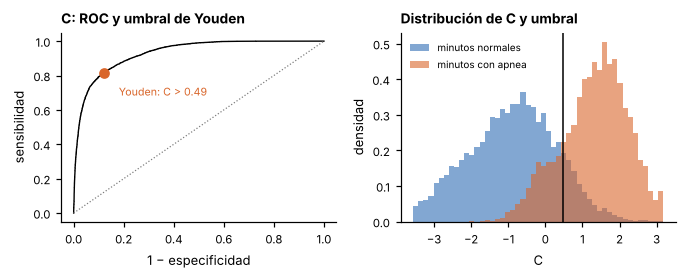

In [15]:
c_all = ev["C"].to_numpy()
pred_c = (c_all > U_C).astype(int)
pred_cv = resultados["C (RR + nivel EDR)"][0]
margen_cv = resultados["C (RR + nivel EDR)"][3]
filas = []
for nombre, pred in (("umbral con todo desarrollo", pred_c), ("validación cruzada por personas", pred_cv)):
    m = metricas(y_all, pred); bs = [metricas(y_all[i], pred[i]) for i in boot_idx[:1000]]
    filas.append({"estimación": nombre, **{k: f"{v:.3f} ({np.percentile([b[k] for b in bs], 2.5):.3f}–{np.percentile([b[k] for b in bs], 97.5):.3f})"
                                          for k, v in m.items()}})
bs_auc = [auc(c_all[i], y_all[i]) for i in boot_idx[:1000]]
print(f"umbral: C > {U_C:.3f} · AUC de C (todos los minutos) {auc(c_all, y_all):.3f} "
      f"(IC 95 % {np.percentile(bs_auc, 2.5):.3f} a {np.percentile(bs_auc, 97.5):.3f})")
fpr, tpr = roc(c_all, y_all); m_ = metricas(y_all, pred_c)
fig, ax = plt.subplots(1, 2, figsize=(ANCHO, 2.6))
ax[0].plot(fpr, tpr, color="black")
ax[0].plot(1 - m_["especificidad"], m_["sensibilidad"], "o", color=APNEA)
ax[0].annotate(f"Youden: C > {U_C:.2f}", (1 - m_["especificidad"], m_["sensibilidad"]), xytext=(10, -15),
               textcoords="offset points", fontsize=7, color=APNEA)
ax[0].plot([0, 1], [0, 1], color=GRIS, ls=":", lw=0.8)
ax[0].set(xlabel="1 − especificidad", ylabel="sensibilidad", title="C: ROC y umbral de Youden")
bins = np.linspace(np.quantile(c_all, 0.005), np.quantile(c_all, 0.995), 50)
ax[1].hist(c_all[y_all == 0], bins=bins, color=NORMAL, alpha=0.6, density=True, label="minutos normales")
ax[1].hist(c_all[y_all == 1], bins=bins, color=APNEA, alpha=0.6, density=True, label="minutos con apnea")
ax[1].axvline(U_C, color="black", lw=1)
ax[1].set(xlabel="C", ylabel="densidad", title="Distribución de C y umbral")
ax[1].legend(loc="upper left", fontsize=6.5)
fig.tight_layout()
save(fig, "04_umbral")
pd.DataFrame(filas).set_index("estimación")

In [16]:
def umbral_criterio(x, y, criterio):
    """Umbral (x > umbral es apnea) elegido con `criterio` sobre la ROC de x."""
    x, y = np.asarray(x, float), np.asarray(y, int)
    o = np.argsort(-x); xs, ys = x[o], y[o]
    se = np.cumsum(ys) / ys.sum(); fp = np.cumsum(1 - ys) / (1 - ys).sum(); sp = 1 - fp
    if criterio == "Youden":
        k = np.argmax(se + sp - 1)
    elif criterio == "más cercano a (0, 1)":
        k = np.argmin((1 - se) ** 2 + fp ** 2)
    elif criterio == "máxima exactitud":
        k = np.argmax((np.cumsum(ys) + (1 - ys).sum() - np.cumsum(1 - ys)) / len(ys))
    elif criterio == "sensibilidad = especificidad":
        k = np.argmin(np.abs(se - sp))
    return float((xs[k] + xs[min(k + 1, len(xs) - 1)]) / 2)

CRITERIOS = ("Youden", "más cercano a (0, 1)", "máxima exactitud", "sensibilidad = especificidad")
filas = []
for criterio in CRITERIOS:
    pred_k = np.zeros(len(ev), int)
    for gpo in grupos:
        te = np.isin(subj, gpo); tr = ~te
        a_w = [auc(c_score(ev[tr], fit_c(ev[tr], w)).to_numpy(), y_all[tr]) for w in GRILLA_W]
        p_ = fit_c(ev[tr], float(GRILLA_W[int(np.argmax(a_w))]))
        u_ = umbral_criterio(c_score(ev[tr], p_).to_numpy(), y_all[tr], criterio)
        pred_k[te] = c_score(ev[te], p_).to_numpy() > u_
    m = metricas(y_all, pred_k)
    nn = ev.assign(p=pred_k).groupby("record").agg(real=("label", "mean"), est=("p", "mean")).join(split.set_index("record").category)
    filas.append({"criterio": criterio, **m, "exactitud balanceada": (m["sensibilidad"] + m["especificidad"]) / 2,
                  "umbral con todo desarrollo": umbral_criterio(c_all, y_all, criterio),
                  "error medio por noche (puntos de %)": 100 * (nn.est - nn.real).abs().mean(),
                  "% marcado en controles": 100 * nn[nn.category == "C"].est.mean()})
pd.DataFrame(filas).set_index("criterio").round(3)

,sensibilidad,especificidad,exactitud,exactitud balanceada,umbral con todo desarrollo,error medio por noche (puntos de %),% marcado en controles
criterio,,,,,,,
Youden,0.814,0.851,0.836,0.832,0.489,14.286,7.376
"más cercano a (0, 1)",0.824,0.839,0.833,0.831,0.394,14.914,7.892
máxima exactitud,0.764,0.899,0.845,0.831,0.596,12.532,5.301
sensibilidad = especificidad,0.831,0.830,0.830,0.830,0.331,15.309,8.816


**Qué se ve.**
- Con personas no vistas, **los cuatro criterios dan la misma exactitud balanceada** (0,830 a 0,832). La ROC es la misma; lo único que cambia es en qué punto de ella se pone el umbral.
- Youden, el punto más cercano a (0, 1) y sensibilidad = especificidad eligen umbrales parecidos (0,33 a 0,49) y casi el mismo balance entre los dos errores.
- La máxima exactitud simple elige un umbral más alto (0,60): gana especificidad (0,899) y pierde sensibilidad (0,764). Con eso sube la exactitud simple y baja el error por noche, pero solo porque en desarrollo el 60 % de los minutos son normales. Esa ventaja depende de la prevalencia de desarrollo y equivale a pesar más las falsas alarmas que las apneas perdidas, sin una razón para hacerlo.

**Se mantiene Youden**: ningún criterio separa mejor los minutos, y es el que no favorece a ninguna clase por ser más numerosa.

## 10. Por noche

La fracción de minutos clasificados como apnea en cada noche (con el detector de la validación cruzada, que no vio a la persona) contra la fracción real.

error medio (estimado − real): +1.7 puntos; controles: 7.4 % de minutos marcados en promedio


,real,estimada,category,error
record,,,,
a18,0.90,0.18,A,-0.71
a09,0.77,0.35,A,-0.43
a19,0.41,0.00,A,-0.41
x09,0.33,0.00,A,-0.33
a17,0.33,0.05,A,-0.28


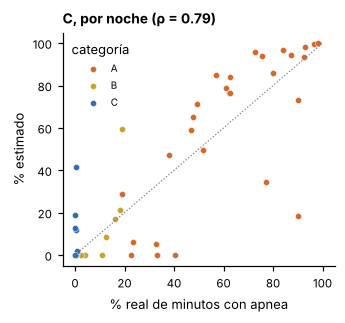

In [17]:
noche = ev.assign(pred=pred_cv).groupby("record").agg(real=("label", "mean"), estimada=("pred", "mean"))
noche = noche.join(split.set_index("record").category)
rho, _ = spearmanr(noche.real, noche.estimada)
fig, ax = plt.subplots(figsize=(3.2, 3.0))
for cat, gr in noche.groupby("category"):
    ax.scatter(100 * gr.real, 100 * gr.estimada, s=16, color=COLORES_CAT[cat], label=cat, edgecolor="white", lw=0.3)
ax.plot([0, 100], [0, 100], color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="% real de minutos con apnea", ylabel="% estimado", title=f"C, por noche (ρ = {rho:.2f})")
ax.legend(loc="upper left", title="categoría", fontsize=6.5)
fig.tight_layout()
save(fig, "04_por_noche")
print(f"error medio (estimado − real): {100 * (noche.estimada - noche.real).mean():+.1f} puntos; "
      f"controles: {100 * noche[noche.category == 'C'].estimada.mean():.1f} % de minutos marcados en promedio")
noche.assign(error=noche.estimada - noche.real).sort_values("error").head(5).round(2)

**Qué se ve.** C ordena las noches según cuánta apnea tienen, con un error medio chico y pocos minutos marcados en los controles. Las noches que más subestima (tabla) son noches con apnea donde el nivel de la EDR queda bajo, así que el RR tiene que superar una vara alta: las dos noches de una misma persona con mucha apnea (`a18`, `a09`) y algunas con apnea moderada (`a19`, `x09`, `a17`) donde casi no marca minutos.

## 11. Dónde falla el detector

Con las predicciones de la validación cruzada (cada minuto clasificado por un detector que no vio a su persona) se busca qué tienen en común los errores: en qué noches, dónde dentro de la noche y por qué.

2033 falsos positivos y 1703 falsos negativos en 22772 minutos; 10 de 47 registros juntan la mitad de los errores


errores a ≤2 min de un cambio de etiqueta: 29 % (esos minutos son el 12 % del total)


,tasa de error,falsos positivos (% de los minutos),falsos negativos (% de los minutos)
primera hora,0.161,0.123,0.038
resto de la noche,0.164,0.085,0.080
20 % con más movimiento,0.232,0.150,0.082
80 % restante,0.147,0.074,0.073


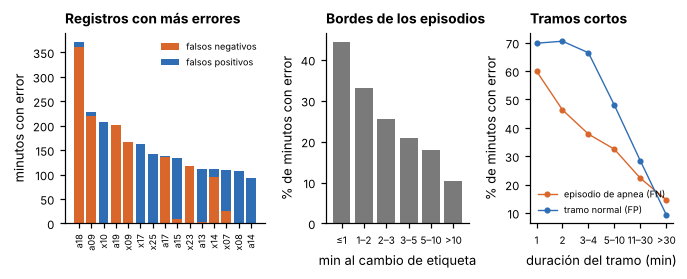

In [18]:
err = ev.assign(pred=pred_cv, margen=margen_cv)
err["FP"] = (err.pred == 1) & (err.label == 0); err["FN"] = (err.pred == 0) & (err.label == 1); err["error"] = err.FP | err.FN
ctx = []
for rec_, g_ in err.groupby("record"):
    lab_ = load_apnea_labels(rec_).astype(int)
    cambios = np.flatnonzero(np.diff(lab_) != 0) + 0.5
    b_ = np.r_[0, np.flatnonzero(np.diff(lab_) != 0) + 1, len(lab_)]; dur = np.zeros(len(lab_), int)
    for a_, e_ in zip(b_[:-1], b_[1:]):
        dur[a_:e_] = e_ - a_
    for m_ in g_.minute:
        ctx.append((rec_, m_, np.min(np.abs(cambios - m_)) if len(cambios) else 999, dur[m_]))
err = err.merge(pd.DataFrame(ctx, columns=["record", "minute", "dist_cambio", "dur_tramo"]), on=["record", "minute"])
por_reg = err.groupby("record").agg(FP=("FP", "sum"), FN=("FN", "sum"), apnea=("label", "mean"))
por_reg["total"] = por_reg.FP + por_reg.FN
por_reg = por_reg.sort_values("total", ascending=False)
mitad = int((por_reg.total.cumsum() / por_reg.total.sum() < 0.5).sum()) + 1
print(f"{int(err.FP.sum())} falsos positivos y {int(err.FN.sum())} falsos negativos en {len(err)} minutos; "
      f"{mitad} de {len(por_reg)} registros juntan la mitad de los errores")

fig, axs = plt.subplots(1, 3, figsize=(ANCHO, 2.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
top = por_reg.head(15)
axs[0].bar(range(len(top)), top.FN, color=APNEA, label="falsos negativos")
axs[0].bar(range(len(top)), top.FP, bottom=top.FN, color=NORMAL, label="falsos positivos")
axs[0].set_xticks(range(len(top))); axs[0].set_xticklabels(top.index, rotation=90, fontsize=6)
axs[0].set(ylabel="minutos con error", title="Registros con más errores")
axs[0].legend(loc="upper right", fontsize=6)
bins_d = [0, 1, 2, 3, 5, 10, 1000]; etq_d = ["≤1", "1–2", "2–3", "3–5", "5–10", ">10"]
tasa_d = err.groupby(pd.cut(err.dist_cambio, bins_d, labels=etq_d), observed=True).error.mean()
axs[1].bar(range(len(tasa_d)), 100 * tasa_d, color=GRIS)
axs[1].set_xticks(range(len(tasa_d))); axs[1].set_xticklabels(etq_d, fontsize=6.5)
axs[1].set(xlabel="min al cambio de etiqueta", ylabel="% de minutos con error", title="Bordes de los episodios")
bins_t = [0, 1, 2, 4, 10, 30, 1000]; etq_t = ["1", "2", "3–4", "5–10", "11–30", ">30"]
for lab_, color, nombre in ((1, APNEA, "episodio de apnea (FN)"), (0, NORMAL, "tramo normal (FP)")):
    g_ = err[err.label == lab_]
    t_ = g_.groupby(pd.cut(g_.dur_tramo, bins_t, labels=etq_t), observed=True).error.mean()
    axs[2].plot(range(len(t_)), 100 * t_, "o-", color=color, ms=3, label=nombre)
axs[2].set_xticks(range(len(etq_t))); axs[2].set_xticklabels(etq_t, fontsize=6.5)
axs[2].set(xlabel="duración del tramo (min)", ylabel="% de minutos con error", title="Tramos cortos")
axs[2].legend(loc="lower left", fontsize=6)
fig.tight_layout()
save(fig, "04_fallas_resumen")
print(f"errores a ≤2 min de un cambio de etiqueta: {100 * err[err.error].dist_cambio.le(2).mean():.0f} % "
      f"(esos minutos son el {100 * err.dist_cambio.le(2).mean():.0f} % del total)")
grupos_ctx = {"primera hora": err.minute < 60, "resto de la noche": err.minute >= 60,
              "20 % con más movimiento": err.mov_rel > err.mov_rel.quantile(0.8), "80 % restante": err.mov_rel <= err.mov_rel.quantile(0.8)}
pd.DataFrame({k: {"tasa de error": err[m].error.mean(), "falsos positivos (% de los minutos)": err[m].FP.mean(),
                  "falsos negativos (% de los minutos)": err[m].FN.mean()} for k, m in grupos_ctx.items()}).T.round(3)

**Qué se ve.**
- **Los errores se concentran en pocas noches, y en cada una van casi siempre para el mismo lado**: noches con muchos falsos negativos y noches con muchos falsos positivos (izquierda).
- **En los bordes de los episodios** la tasa de error es varias veces mayor que lejos de ellos (centro): la ventana de 240 s mezcla minutos de los dos tipos y la etiqueta cambia de golpe.
- **Los tramos cortos** se clasifican mal (derecha): los episodios de 1–2 minutos se pierden con frecuencia, y los tramos normales cortos entre apneas se marcan como apnea. Es el límite de resolución de la ventana (limitación 5).
- En los minutos con más movimiento la tasa de error es mayor. En la primera hora (vigilia) la tasa total es parecida al resto, pero hay más falsos positivos y menos falsos negativos (tabla).

¿Por qué hay noches enteras corridas para un lado? En C el nivel de la EDR fija la vara de toda la noche. Si ese nivel no corresponde a la cantidad de apnea de la noche, todos los minutos se corren juntos. Se compara, para cada noche, cuánto se aparta su nivel de EDR de lo esperado para su % de apnea (residuo de una recta) con su error de estimación.

,real,nivel_edr,estimada,residuo_edr,error_noche
record,,,,,
a18,0.899,-1.812,0.185,-0.375,-0.715
a09,0.773,-1.830,0.347,-0.200,-0.426
a19,0.406,-2.502,0.000,-0.312,-0.406
x09,0.331,-2.561,0.000,-0.257,-0.331
a17,0.328,-2.498,0.053,-0.189,-0.276
a13,0.492,-1.719,0.712,0.340,0.220
a15,0.729,-1.445,0.956,0.253,0.228
x25,0.570,-1.597,0.851,0.343,0.281
x10,0.190,-1.680,0.597,0.841,0.407


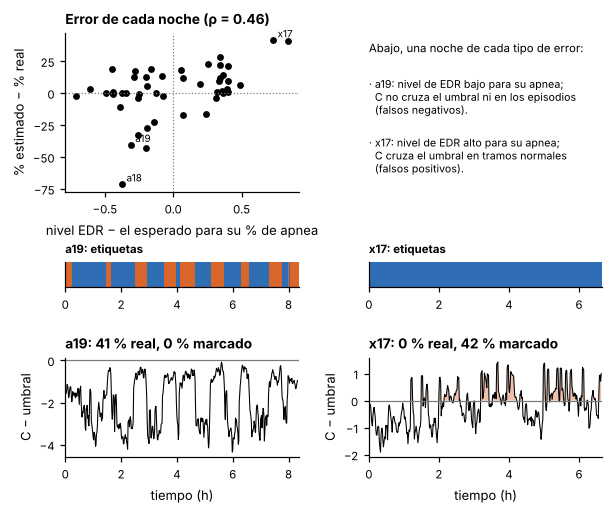

In [19]:
noc = err.groupby("record").agg(real=("label", "mean"), nivel_edr=("EDR_noche", "first"), estimada=("pred", "mean"))
recta = np.polyfit(noc.real, noc.nivel_edr, 1)
noc["residuo_edr"] = noc.nivel_edr - np.polyval(recta, noc.real); noc["error_noche"] = noc.estimada - noc.real
rho_r = spearmanr(noc.residuo_edr, noc.error_noche)[0]
fn_tipo = noc.error_noche.idxmin() if noc.error_noche.idxmin() not in ("a18", "a09") else noc[~noc.index.isin(["a18", "a09"])].error_noche.idxmin()
fp_tipo = noc.error_noche.idxmax()
fig = plt.figure(figsize=(ANCHO, 5.0))
gs11 = fig.add_gridspec(3, 2, height_ratios=[1.6, 0.25, 1.0], hspace=0.75, wspace=0.3)
ax = fig.add_subplot(gs11[0, 0])
ax.scatter(noc.residuo_edr, 100 * noc.error_noche, s=12, color="black")
for r_ in (fn_tipo, fp_tipo, "a18"):
    ax.annotate(r_, (noc.residuo_edr[r_], 100 * noc.error_noche[r_]), fontsize=6.5, xytext=(3, 2), textcoords="offset points")
ax.axhline(0, color=GRIS, ls=":", lw=0.8); ax.axvline(0, color=GRIS, ls=":", lw=0.8)
ax.set(xlabel="nivel EDR − el esperado para su % de apnea", ylabel="% estimado − % real", title=f"Error de cada noche (ρ = {rho_r:.2f})")
for j, rec_ in enumerate((fn_tipo, fp_tipo)):
    g_ = err[err.record == rec_].sort_values("minute"); lab_ = load_apnea_labels(rec_)
    axl = fig.add_subplot(gs11[1, j]); label_strip(axl, lab_, unit=60); axl.set_title(f"{rec_}: etiquetas", fontsize=7.5)
    axm = fig.add_subplot(gs11[2, j], sharex=axl)
    axm.plot(g_.minute / 60, g_.margen, color="black", lw=0.7)
    axm.fill_between(g_.minute / 60, 0, g_.margen, where=g_.margen > 0, color=APNEA, alpha=0.4, lw=0)
    axm.axhline(0, color=GRIS, lw=0.8)
    axm.set(xlabel="tiempo (h)", ylabel="C − umbral", title=f"{rec_}: {100 * g_.label.mean():.0f} % real, {100 * g_.pred.mean():.0f} % marcado", )
ax_t = fig.add_subplot(gs11[0, 1]); ax_t.axis("off")
ax_t.text(0, 0.95, "Abajo, una noche de cada tipo de error:", fontsize=7.5, va="top")
ax_t.text(0, 0.72, f"· {fn_tipo}: nivel de EDR bajo para su apnea;\n  C no cruza el umbral ni en los episodios\n  (falsos negativos).", fontsize=7, va="top")
ax_t.text(0, 0.35, f"· {fp_tipo}: nivel de EDR alto para su apnea;\n  C cruza el umbral en tramos normales\n  (falsos positivos).", fontsize=7, va="top")
save(fig, "04_fallas_noches")
noc.sort_values("error_noche").round(3).iloc[np.r_[0:5, -5:0]]

**Qué se ve.** Las noches cuyo nivel de EDR queda por debajo de lo esperado para su cantidad de apnea son las que se subestiman, y las que quedan por encima, las que se sobreestiman (ρ positivo). En la noche con falsos negativos, C sube durante los episodios —el RR los marca— pero toda la noche está corrida hacia abajo y casi nunca cruza el umbral; en la de falsos positivos pasa lo contrario. **Este es el fallo principal del detector**: el nivel de la EDR estima la cantidad de apnea de cada noche solo de forma aproximada (`03`: en algunas personas la EDR sigue mal a la respiración), y cuando se equivoca arrastra a toda la noche.

## 12. Confianza según el movimiento

En `03` se vio que el movimiento altera la EDR, y en los minutos con movimiento la potencia lenta sube aunque no haya apnea. Para cada minuto se mide el movimiento sin etiquetas: la varianza del ECG crudo por debajo de 0,5 Hz en la ventana de 240 s, relativa a la mediana de esa noche (log₁₀). Se mira si el detector acierta menos cuando hay más movimiento.

cortes de movimiento (log10 respecto de la noche): media > -0.001, baja > 0.702


,% de minutos,sensibilidad,especificidad,exactitud,% con apnea
confianza,,,,,
alta,50.000,0.819,0.912,0.876,38.776
media,39.996,0.808,0.868,0.842,42.907
baja,10.004,0.851,0.773,0.802,36.567


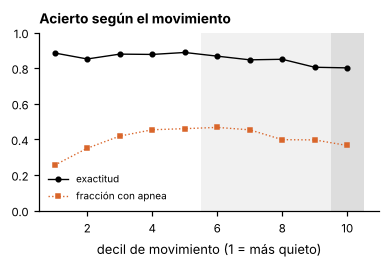

In [20]:
ev["mov_dec"] = pd.qcut(ev.mov_rel, 10, labels=False)
por_mov = ev.assign(acierto=(pred_c == y_all)).groupby("mov_dec").agg(exactitud=("acierto", "mean"),
                                                                      apnea=("label", "mean"))
CORTES = (float(ev.mov_rel.quantile(0.5)), float(ev.mov_rel.quantile(0.9)))
ev["confianza"] = confidence(ev.mov_rel, CORTES)
filas = []
for c_ in ("alta", "media", "baja"):
    sel = (ev.confianza == c_).to_numpy()
    filas.append({"confianza": c_, "% de minutos": 100 * sel.mean(), **metricas(y_all[sel], pred_c[sel]),
                  "% con apnea": 100 * y_all[sel].mean()})
fig, ax = plt.subplots(figsize=(3.6, 2.5))
ax.plot(por_mov.index + 1, por_mov.exactitud, "o-", color="black", ms=3, label="exactitud")
ax.plot(por_mov.index + 1, por_mov.apnea, "s:", color=APNEA, ms=3, label="fracción con apnea")
ax.axvspan(5.5, 9.5, color=GRIS, alpha=0.1, lw=0); ax.axvspan(9.5, 10.5, color=GRIS, alpha=0.25, lw=0)
ax.set(xlabel="decil de movimiento (1 = más quieto)", ylim=(0, 1), title="Acierto según el movimiento")
ax.legend(loc="lower left", fontsize=6.5)
fig.tight_layout()
save(fig, "04_confianza")
print(f"cortes de movimiento (log10 respecto de la noche): media > {CORTES[0]:.3f}, baja > {CORTES[1]:.3f}")
pd.DataFrame(filas).set_index("confianza").round(3)

**Qué se ve.** La exactitud se mantiene en ~0,88 en la mitad más quieta y baja a ~0,80 en el 20 % con más movimiento. El efecto es más chico que con F: en C la EDR entra solo como nivel de la noche, así que el movimiento de un minuto no la afecta; solo afecta al RR. La fracción de minutos con apnea no es pareja (es menor en los minutos más quietos, porque los despertares al final de cada apnea generan movimiento), así que la confianza no es independiente de la respuesta; por eso solo se informa y no cambia la decisión. Se define la **confianza** de cada decisión: **alta** en el 50 % de minutos más quietos, **media** hasta el percentil 90 y **baja** en el 10 % con más movimiento (cortes de desarrollo, fijos para test). El detector decide en todos los minutos e informa la confianza al lado.

## 13. Por qué la EDR es relativa: el efecto en la detección

En `03` (sección 7) se mostró, sin etiquetas, que la oscilación de la EDR en mV·ms crece con el tamaño del QRS de cada persona y que dividida por ese tamaño deja de depender de él. En C la EDR entra solo como nivel de la noche, así que el tamaño del QRS movería ese nivel sin relación con la apnea. Se compara C con la EDR relativa (la que se usa) y con la EDR en mV·ms; como la potencia va con el cuadrado de la amplitud, el nivel en mV·ms es el relativo más 2·log₁₀ del tamaño del QRS.

,nivel EDR vs % de apnea (ρ),AUC de C,sensibilidad,especificidad,exactitud,ρ por noche,% marcado en controles
EDR,,,,,,,
EDR en mV·ms,0.713,0.891,0.796,0.817,0.808,0.768,2.812
EDR relativa,0.825,0.931,0.817,0.881,0.855,0.819,6.143


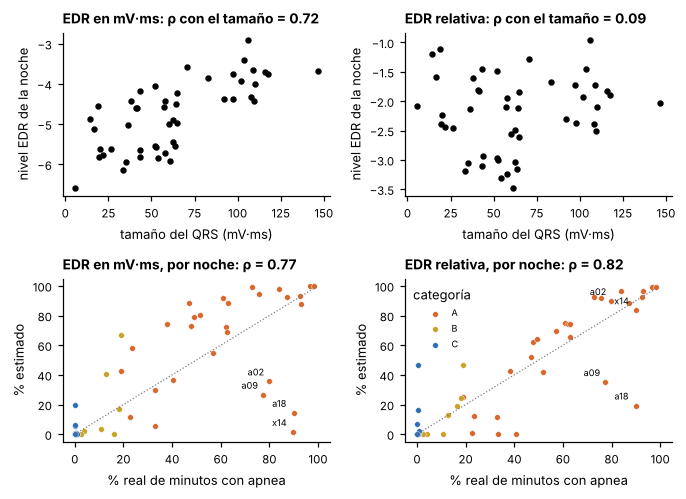

In [21]:
ev["EDR_noche (mV·ms)"] = ev["EDR_noche"] + 2 * np.log10(ev["escala_qrs"])
tam_qrs = ev.groupby("record").escala_qrs.first() * 1000
niv = ev.groupby("record")[["EDR_noche", "EDR_noche (mV·ms)"]].first().join(ev.groupby("record").label.mean().rename("frac"))
comp_escala = []
fig, axs = plt.subplots(2, 2, figsize=(ANCHO, 4.6))
for j, (col, titulo) in enumerate((("EDR_noche (mV·ms)", "EDR en mV·ms"), ("EDR_noche", "EDR relativa"))):
    axs[0, j].scatter(tam_qrs[niv.index], niv[col], s=10, color="black")
    axs[0, j].set(xlabel="tamaño del QRS (mV·ms)", ylabel="nivel EDR de la noche",
                  title=f"{titulo}: ρ con el tamaño = {spearmanr(tam_qrs[niv.index], niv[col])[0]:.2f}")
    e_ = ev.rename(columns={col: "_edr"}).assign(EDR_noche=lambda t: t["_edr"])
    p_ = fit_c(e_, W_FINAL, "P_RR"); s_ = c_score(e_, p_).to_numpy(); u_ = youden_threshold(s_, y_all); pr_ = (s_ > u_).astype(int)
    nn = ev.assign(p=pr_).groupby("record").agg(real=("label", "mean"), estimada=("p", "mean")).join(split.set_index("record").category)
    for cat, gr in nn.groupby("category"):
        axs[1, j].scatter(100 * gr.real, 100 * gr.estimada, s=14, color=COLORES_CAT[cat], edgecolor="white", lw=0.3, label=cat)
    for rec_ in ("a02", "x14", "a09", "a18"):
        axs[1, j].annotate(rec_, (100 * nn.real[rec_], 100 * nn.estimada[rec_]), fontsize=6, xytext=(-14, 4), textcoords="offset points")
    axs[1, j].plot([0, 100], [0, 100], color=GRIS, ls=":", lw=0.8)
    axs[1, j].set(xlabel="% real de minutos con apnea", ylabel="% estimado",
                  title=f"{titulo}, por noche: ρ = {spearmanr(nn.real, nn.estimada)[0]:.2f}")
    m_ = metricas(y_all, pr_)
    comp_escala.append({"EDR": titulo, "nivel EDR vs % de apnea (ρ)": spearmanr(niv[col], niv.frac)[0],
                        "AUC de C": auc(s_, y_all), **m_, "ρ por noche": spearmanr(nn.real, nn.estimada)[0],
                        "% marcado en controles": 100 * nn[nn.category == "C"].estimada.mean()})
axs[1, 1].legend(loc="upper left", fontsize=6, title="categoría")
fig.tight_layout()
save(fig, "04_escala_edr")
pd.DataFrame(comp_escala).set_index("EDR").round(3)

**Qué se ve.** Con la EDR en mV·ms, el nivel de la noche depende del tamaño del QRS de la persona (ρ alto con el tamaño); con la EDR relativa esa dependencia casi desaparece y el nivel acompaña mejor a la cantidad de apnea. `a02` y `x14`, de una persona con el QRS chico, pasan de casi no detectarse a estimarse bien. `a09` y `a18`, de otra persona, siguen subestimadas: su nivel de EDR es bajo por algo que no es el tamaño del QRS. A cambio, con la EDR relativa se marcan algo más de minutos en los controles.

## 14. Las predicciones en desarrollo y lo que queda fijo para test

Las tres predicciones de la hipótesis, medidas en desarrollo con el mismo criterio que se va a usar en test (intervalos al 95 % por bootstrap de personas):

In [22]:
# P1: AUC dentro de la noche de P_RR
d1 = dentro["RR (Welch)"].to_numpy(); suj1 = dentro.subject.to_numpy(); us1 = np.unique(suj1)
b1 = [np.mean(np.concatenate([d1[suj1 == u] for u in rng.choice(us1, len(us1))])) for _ in range(4000)]
# P2: Spearman entre el nivel nocturno de la EDR y el % de apnea
suj2 = niv.index.map(SUJETO).to_numpy(); us2 = np.unique(suj2)
b2 = []
for _ in range(4000):
    i_ = np.concatenate([np.flatnonzero(suj2 == u) for u in rng.choice(us2, len(us2))])
    b2.append(spearmanr(niv.EDR_noche.to_numpy()[i_], niv.frac.to_numpy()[i_])[0])
pred_dev = pd.DataFrame([
    {"predicción": "P1 · AUC dentro de la noche del RR (media)", "valor": d1.mean(), "IC 95 %": f"{np.percentile(b1, 2.5):.3f} a {np.percentile(b1, 97.5):.3f}", "criterio": "> 0,5"},
    {"predicción": "P2 · ρ nivel EDR de la noche vs % de apnea", "valor": spearmanr(niv.EDR_noche, niv.frac)[0], "IC 95 %": f"{np.percentile(b2, 2.5):.3f} a {np.percentile(b2, 97.5):.3f}", "criterio": "> 0"},
    {"predicción": "P3 · AUC de C con todos los minutos", "valor": auc(c_all, y_all), "IC 95 %": f"{np.percentile(bs_auc, 2.5):.3f} a {np.percentile(bs_auc, 97.5):.3f}", "criterio": "> 0,5"},
]).set_index("predicción")

PARAMS = {"feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
          **{k: P_C[k] for k in ("mu1", "s1", "mu2", "s2", "w")}, "umbral": U_C,
          "cortes_confianza_mov_rel": list(CORTES), "banda_hz": list(BANDA), "ventana_s": W,
          "minutos_evaluados": "label >= 0 y q <= 0.2", "fijado_con": "47 registros de desarrollo (notebooks/04_feature_y_detector.ipynb)"}
save_params(ROOT / "docs" / "parametros_test.json", PARAMS)
print(json.dumps(PARAMS, indent=2, ensure_ascii=False))
pred_dev.round(3)

{
  "feature": "C(m) = (P_RR(m) - mu1)/s1 + w * (mediana_noche(P_EDR) - mu2)/s2",
  "mu1": -1.4915729639776574,
  "s1": 0.5902302539907761,
  "mu2": -2.1968125649714527,
  "s2": 0.6360237250552897,
  "w": 1.0,
  "umbral": 0.4892473148877837,
  "cortes_confianza_mov_rel": [
    -0.0006714851856341618,
    0.702342604285502
  ],
  "banda_hz": [
    0.01,
    0.05
  ],
  "ventana_s": 240,
  "minutos_evaluados": "label >= 0 y q <= 0.2",
  "fijado_con": "47 registros de desarrollo (notebooks/04_feature_y_detector.ipynb)"
}


,valor,IC 95 %,criterio
predicción,,,
P1 · AUC dentro de la noche del RR (media),0.908,0.862 a 0.937,"> 0,5"
P2 · ρ nivel EDR de la noche vs % de apnea,0.825,0.673 a 0.886,> 0
P3 · AUC de C con todos los minutos,0.931,0.895 a 0.964,"> 0,5"


**Por qué las tres predicciones no necesitan corrección por comparaciones múltiples.** H se sostiene solo si se cumplen **las tres**. Es una prueba de unión-intersección: se rechaza la hipótesis nula general ("H no vale") solo si se rechaza cada una de las tres nulas por separado. Berger (1982) mostró que en ese caso la probabilidad de error de toda la prueba no supera el nivel α con que se evalúa cada parte, así que cada predicción se evalúa con su IC del 95 % sin corregir. La corrección haría falta si bastara con que se cumpliera una cualquiera; en cambio, las comparaciones de la sección 8 son muchas y cualquiera podría salir por azar, y por eso ahí sí se corrige.

Las tres predicciones se cumplen en desarrollo. Eso era de esperar, porque la hipótesis se armó mirando estos datos: la prueba real es test (`05`), que se corre **una sola vez** leyendo `docs/parametros_test.json`, sin tocar nada de este notebook.

| Qué | Valor |
|---|---|
| Feature | C(m) = [P_RR(m) − μ₁]/σ₁ + w·[P̄_EDR − μ₂]/σ₂ (definiciones en `docs/objetivos_hipotesis.md`) |
| Parámetros y umbral | los de `docs/parametros_test.json` (impresos arriba) |
| Confianza | alta / media / baja según el movimiento, con los cortes de desarrollo |
| Predicciones | P1, P2 y P3 con el criterio de la tabla |
| Preguntas secundarias | C contra F y contra el RR solo; exactitud según la confianza; estimación por noche |

## 15. ¿Dependen los resultados de las decisiones de diseño?

Varias decisiones se justificaron por razones físicas o por convención, sin comparar alternativas. Acá se repite toda la validación cruzada de C (por personas, 5 grupos, peso y umbral elegidos en cada grupo) cambiando una decisión por vez:

| Decisión | Actual | Alternativas | Por qué la actual |
|---|---|---|---|
| Ventana | 240 s | 180, 300, 360 s | Con segmentos de 120 s la banda empieza en 0,017 Hz, con dos ciclos por segmento (sección 1) |
| Interpolación a 2 Hz | cúbica | lineal | Curva suave, con derivada continua (sección 1) |
| Tendencia en cada segmento de Welch | se quita una recta | no quitar nada; quitar solo la media | Ver la figura de abajo |
| Alineación de la ventana | centrada en el minuto | terminada al final del minuto (solo datos pasados) | El análisis es fuera de línea; centrada usa el contexto de los dos lados |
| Banda de la EDR | 0,017–0,05 Hz | 0,017–0,033 Hz (su banda a −3 dB, `01` §7) | La misma banda para las dos señales |
| Escala de las potencias | log₁₀ | lineal | La potencia varía en órdenes de magnitud entre minutos y personas |
| Nivel nocturno de la EDR | mediana | media | La mediana no se deja llevar por los minutos con movimiento |
| Grupos de la validación cruzada | 5 | 10; una persona por grupo | ~4 personas por grupo (Arlot y Celisse, 2010) |
| Primera hora (vigilia) | se evalúa | excluida | Las etiquetas de la base cubren toda la noche |

**Por qué quitar la tendencia.** El método de Welch supone que cada segmento es estacionario. Una tendencia lenta dentro del segmento de 120 s (la frecuencia cardíaca que baja de a poco al dormirse, por ejemplo) no es una oscilación, pero tiene energía: sobre todo en la frecuencia más baja del espectro (k = 1, por debajo de la banda), y una parte se filtra a todas las demás. Quitar la tendencia antes del análisis espectral es práctica habitual en variabilidad cardíaca (Tarvainen et al., 2002). La figura lo muestra con una señal armada a propósito: una oscilación de 40 s, con y sin una deriva lineal.

potencia en la banda respecto de la señal sin deriva: quitando la media ×0.9 · quitando la recta ×0.99


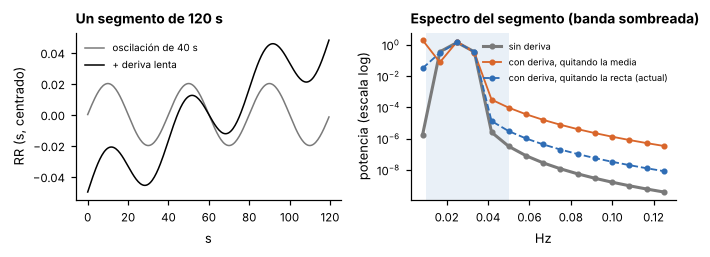

In [23]:
from scipy.signal import detrend as _detrend

t_s = np.arange(0, 120, 1 / FSU)
osc = 0.02 * np.sin(2 * np.pi * t_s / 40)
deriva = 0.10 * (t_s / 120 - 0.5)
win_h = np.hanning(len(t_s)); f_s = np.fft.rfftfreq(len(t_s), 1 / FSU)
psd = lambda x_: np.abs(np.fft.rfft(x_ * win_h)) ** 2
fig, axs = plt.subplots(1, 2, figsize=(ANCHO, 2.4))
axs[0].plot(t_s, osc, color=GRIS, lw=1, label="oscilación de 40 s")
axs[0].plot(t_s, osc + deriva, color="black", lw=1, label="+ deriva lenta")
axs[0].set(xlabel="s", ylabel="RR (s, centrado)", title="Un segmento de 120 s")
axs[0].legend(fontsize=6.5)
for x_, et, est in ((osc, "sin deriva", dict(color=GRIS, lw=2)),
                    (osc + deriva - (osc + deriva).mean(), "con deriva, quitando la media", dict(color=APNEA, lw=1.2)),
                    (_detrend(osc + deriva, type="linear"), "con deriva, quitando la recta (actual)", dict(color=NORMAL, lw=1.2, ls="--"))):
    axs[1].semilogy(f_s[1:16], psd(x_)[1:16], marker="o", ms=3, label=et, **est)
axs[1].axvspan(BANDA[0], BANDA[1], color=NORMAL, alpha=0.1, lw=0)
axs[1].set(xlabel="Hz", ylabel="potencia (escala log)", title="Espectro del segmento (banda sombreada)")
axs[1].legend(fontsize=6)
fig.tight_layout()
save(fig, "04_tendencia")
fb = (f_s >= BANDA[0] - 1e-9) & (f_s <= BANDA[1] + 1e-9)
print("potencia en la banda respecto de la señal sin deriva: quitando la media "
      f"×{psd(osc + deriva - (osc + deriva).mean())[fb].sum() / psd(osc)[fb].sum():.1f} · quitando la recta "
      f"×{psd(_detrend(osc + deriva, type='linear'))[fb].sum() / psd(osc)[fb].sum():.2f}")

Con solo quitar la media, la deriva deja mucha energía en k = 1, distorsiona el primer punto de la banda y sube 10 a 100 veces el espectro fuera del pico; quitando la recta, el espectro vuelve casi al de la oscilación sola. Como el pico de 40 s domina, la potencia total en la banda cambia poco en este ejemplo (número impreso arriba): la ventana de Hann ya concentra la deriva en las frecuencias más bajas. Ahora todas las variantes, con los datos de desarrollo:

In [24]:
import src.features.build as build_mod
import src.features.coupling as coup_mod
import src.features.detector as det_mod
from src.features.coupling import resample_uniform as _ru

def _tabla_variante(args):
    rec_, op = args
    det_mod.WINDOW_S = op.get("ventana", 240)
    coup_mod.WELCH_DETREND = op.get("detrend", "linear")
    if op.get("interp") == "lineal":
        build_mod.resample_uniform = lambda t, x, fs=2.0: _ru(t, x, fs, "linear")
    return det_mod.minute_table(rec_, centered=op.get("centered", True), band_edr=op.get("band_edr"))

def _preparar(T_, nivel="median", escala="log"):
    T_ = T_.assign(subject=T_.record.map(SUJETO))
    if escala == "lineal":
        T_ = T_.assign(P_RR=10 ** T_.P_RR, P_EDR=10 ** T_.P_EDR)
    T_["EDR_noche"] = T_.groupby("record").P_EDR.transform(nivel)
    return T_

def _cv_c(T_, nivel="median", escala="log", n_grupos=5, sin_primera_hora=False):
    T_ = _preparar(T_, nivel, escala)
    e_ = T_[det_mod.evaluable(T_)]
    if sin_primera_hora:
        e_ = e_[e_.minute >= 60]
    e_ = e_.reset_index(drop=True); yy = e_.label.to_numpy(); ss = e_.subject.to_numpy()
    pr = np.zeros(len(e_), int); aa = []
    for gpo in np.array_split(np.random.default_rng(2026).permutation(np.unique(ss)), n_grupos):
        te = np.isin(ss, gpo); tr = ~te
        w_ = GRILLA_W[int(np.argmax([auc(c_score(e_[tr], fit_c(e_[tr], w)).to_numpy(), yy[tr]) for w in GRILLA_W]))]
        p_ = fit_c(e_[tr], w_); u_ = youden_threshold(c_score(e_[tr], p_).to_numpy(), yy[tr])
        s_ = c_score(e_[te], p_).to_numpy(); pr[te] = s_ > u_
        if 0 < yy[te].sum() < te.sum():
            aa.append(auc(s_, yy[te]))
    den = [auc(g_.P_RR.to_numpy(), g_.label.to_numpy()) for _, g_ in e_.groupby("record")
           if min((g_.label == 1).sum(), (g_.label == 0).sum()) >= MIN_MINUTES_PER_CLASS]
    nn = e_.assign(p=pr).groupby("record").agg(real=("label", "mean"), est=("p", "mean"))
    acierto = e_.assign(ok=(pr == yy)).groupby("subject").ok.agg(["sum", "size"])
    return {**metricas(yy, pr), "AUC (personas no vistas)": float(np.mean(aa)), "AUC dentro de la noche": float(np.mean(den)),
            "ρ por noche": spearmanr(nn.real, nn.est)[0]}, acierto

VARIANTES_T = {
    "actual": {}, "interpolación lineal": {"interp": "lineal"},
    "ventana de 180 s": {"ventana": 180}, "ventana de 300 s": {"ventana": 300}, "ventana de 360 s": {"ventana": 360},
    "sin quitar la tendencia": {"detrend": "none"}, "quitando solo la media": {"detrend": "constant"},
    "ventana hacia atrás (solo pasado)": {"centered": False}, "EDR en 0,01–0,033 Hz": {"band_edr": (0.01, 0.034)},
}
tablas_t = {}
for nombre, op in VARIANTES_T.items():
    with ProcessPoolExecutor(4) as ex:
        tablas_t[nombre] = pd.concat(list(ex.map(_tabla_variante, [(r, op) for r in DEV])), ignore_index=True)
T_base = tablas_t["actual"]
VARIANTES_CV = {nombre: (tabla_, {}) for nombre, tabla_ in tablas_t.items()}
VARIANTES_CV.update({
    "potencias en escala lineal": (T_base, {"escala": "lineal"}), "nivel nocturno = media": (T_base, {"nivel": "mean"}),
    "10 grupos": (T_base, {"n_grupos": 10}), "una persona por grupo": (T_base, {"n_grupos": T_base.record.map(SUJETO).nunique()}),
    "sin la primera hora": (T_base, {"sin_primera_hora": True}),
})
res_t, acierto_t = {}, {}
for nombre, (tabla_, kw) in VARIANTES_CV.items():
    res_t[nombre], acierto_t[nombre] = _cv_c(tabla_, **kw)
rng_t = np.random.default_rng(2026)
pers_t = acierto_t["actual"].index.to_numpy()
sorteos_t = [rng_t.choice(pers_t, len(pers_t)) for _ in range(2000)]
filas = []; fam_rob = {}
for nombre in VARIANTES_CV:
    a_v, a_0 = acierto_t[nombre].reindex(pers_t), acierto_t["actual"]
    dif_ = [(a_v["sum"][so].sum() / a_v["size"][so].sum()) - (a_0["sum"][so].sum() / a_0["size"][so].sum()) for so in sorteos_t]
    lo, hi = np.nanpercentile(dif_, [2.5, 97.5])
    if nombre != "actual":
        fam_rob[nombre] = (res_t[nombre]["exactitud"] - res_t["actual"]["exactitud"], np.array(dif_))
    filas.append({"variante": nombre, **res_t[nombre],
                  "exactitud − actual (IC 95 %)": "—" if nombre == "actual" else
                  f"{res_t[nombre]['exactitud'] - res_t['actual']['exactitud']:+.3f} ({lo:+.3f} a {hi:+.3f})"})
tabla_robustez = pd.DataFrame(filas).set_index("variante").round(3)
display(tabla_robustez)
print("Corrección de Holm sobre las 13 diferencias de exactitud con la versión actual:")
tabla_holm(fam_rob).round(4)

,sensibilidad,especificidad,exactitud,AUC (personas no vistas),AUC dentro de la noche,ρ por noche,exactitud − actual (IC 95 %)
variante,,,,,,,
actual,0.814,0.851,0.836,0.907,0.908,0.795,—
interpolación lineal,0.814,0.843,0.831,0.911,0.908,0.802,-0.005 (-0.015 a +0.004)
ventana de 180 s,0.803,0.840,0.826,0.903,0.895,0.792,-0.010 (-0.017 a -0.003)
ventana de 300 s,0.802,0.842,0.826,0.901,0.903,0.782,-0.010 (-0.020 a -0.001)
ventana de 360 s,0.812,0.833,0.824,0.897,0.899,0.785,-0.011 (-0.019 a -0.005)
sin quitar la tendencia,0.805,0.861,0.838,0.907,0.907,0.800,+0.002 (-0.001 a +0.006)
quitando solo la media,0.805,0.861,0.838,0.907,0.907,0.800,+0.002 (-0.001 a +0.006)
ventana hacia atrás (solo pasado),0.814,0.842,0.830,0.903,0.894,0.805,-0.005 (-0.010 a -0.001)
"EDR en 0,01–0,033 Hz",0.819,0.829,0.825,0.909,0.908,0.793,-0.011 (-0.021 a -0.002)


Corrección de Holm sobre las 13 diferencias de exactitud con la versión actual:


,diferencia,p,p de Holm,significativa sin corregir,resiste Holm
comparación,,,,,
ventana de 360 s,-0.0115,0.000,0.000,sí,sí
potencias en escala lineal,-0.0520,0.002,0.024,sí,sí
ventana de 180 s,-0.0104,0.005,0.055,sí,no
"EDR en 0,01–0,033 Hz",-0.0108,0.007,0.070,sí,no
ventana hacia atrás (solo pasado),-0.0055,0.013,0.117,sí,no
ventana de 300 s,-0.0103,0.023,0.184,sí,no
sin quitar la tendencia,0.0024,0.197,1.000,no,no
quitando solo la media,0.0024,0.197,1.000,no,no
una persona por grupo,0.0061,0.297,1.000,no,no


**Qué se ve** (diferencias de exactitud con IC 95 % por bootstrap de personas; son controles de robustez, no hipótesis, así que se leen como orientativos):
- **Ventana:** 240 s es la mejor; 180, 300 y 360 s bajan la exactitud ~0,01 y también el AUC dentro de la noche. Con la corrección de Holm sobre las 13 variantes, solo la caída con 360 s es significativa (180 s queda en 0,055 y 300 s en 0,18): ninguna ventana es mejor que 240 s, aunque solo con 360 s se demuestra que es peor.
- **Interpolación:** lineal y cúbica son equivalentes (−0,005, intervalo con el cero).
- **Tendencia:** no quitarla o quitar solo la media da lo mismo (+0,002, intervalo con el cero), como anticipaba la figura. Se mantiene quitar la recta como protección: no cuesta nada y evita que una deriva fuerte distorsione la banda.
- **Ventana hacia atrás:** usar solo datos pasados tiende a empeorar (−0,005; significativo sin corregir, p de Holm 0,12) y separa peor dentro de la noche (AUC 0,894 contra 0,908): el contexto de los dos lados del minuto ayuda a ubicar la apnea. Como el análisis es fuera de línea (la noche ya está grabada), no hay razón para renunciar a él.
- **Banda de la EDR:** limitarla a 0,017–0,033 Hz (k = 2…4; en la tabla figura con su borde nominal, 0,01–0,033 Hz) tiende a empeorar (−0,011; significativo sin corregir, p de Holm 0,07). No es mejor, así que se mantiene la misma banda para las dos señales.
- **Escala lineal:** es la peor variante por lejos (−0,052, resiste la corrección de Holm; el ρ por noche cae a 0,66). En escala lineal unas pocas noches con muchísima potencia dominan la media y el desvío de la estandarización; el logaritmo es lo que hace que C funcione.
- **Media en lugar de mediana** para el nivel nocturno: lo mismo (−0,001). Se mantiene la mediana, robusta a minutos con movimiento, sin costo.
- **Grupos de la validación cruzada:** con 10 grupos o con una persona por grupo la exactitud estimada es la misma (−0,001 y +0,006, intervalos con el cero). El AUC medio por grupo baja con una persona por grupo porque muchos grupos tienen casi una sola clase; por eso se usan 5 grupos, el compromiso habitual entre sesgo y varianza (Arlot y Celisse, 2010).
- **Sin la primera hora:** la exactitud no cambia (−0,004) y el AUC dentro de la noche sube un poco (0,919): la vigilia agrega algunos falsos positivos (sección 11). Se evalúa toda la noche porque así está planteada la tarea de la base (todas las horas tienen etiqueta).

### Mínimo de minutos por noche y cantidad de remuestreos

**¿Por qué al menos 20 minutos de cada tipo para el AUC de una noche?** El error estándar del AUC depende de cuántos casos de cada clase hay. Hanley y McNeil (1982) dan una fórmula cerrada para estimarlo; con un AUC de 0,9, 20 minutos de cada tipo dejan un error estándar de ~0,05. La figura muestra cómo cae ese error con más minutos y cómo cambia el AUC medio dentro de la noche (y cuántas noches entran) con otros mínimos.

**Nota del 2026-11-21 (`10` §1).** Con el detector final y un bootstrap que repite la validación cruzada en cada sorteo, **ninguna de las 13 variantes cambia la exactitud de forma demostrable** (p de Holm = 1 en todas). Las dos diferencias que acá resistían Holm, la ventana de 360 s y la escala lineal, no resisten: −0,002 (p = 0,28) y −0,065 (IC −0,120 a +0,013; p = 0,086). Las decisiones no cambian: ninguna variante es mejor, y cada una tiene su razón física o de método en la tabla del principio de esta sección.

,noches,AUC dentro de la noche (media),"error estándar con AUC 0,9 (Hanley y McNeil)"
mínimo de minutos de cada tipo,,,
10,34,0.906,0.074
15,33,0.906,0.060
20,31,0.908,0.051
30,31,0.908,0.042
40,30,0.906,0.036


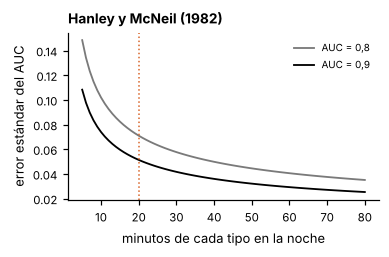

In [25]:
def se_hanley(a_, n1, n0):
    q1, q2 = a_ / (2 - a_), 2 * a_ ** 2 / (1 + a_)
    return np.sqrt((a_ * (1 - a_) + (n1 - 1) * (q1 - a_ ** 2) + (n0 - 1) * (q2 - a_ ** 2)) / (n1 * n0))

ns = np.arange(5, 81)
e_base = T_base[det_mod.evaluable(T_base)]
filas_min = []
for m_min in (10, 15, 20, 30, 40):
    den_ = [auc(g_.P_RR.to_numpy(), g_.label.to_numpy()) for _, g_ in e_base.groupby("record")
            if min((g_.label == 1).sum(), (g_.label == 0).sum()) >= m_min]
    filas_min.append({"mínimo de minutos de cada tipo": m_min, "noches": len(den_), "AUC dentro de la noche (media)": np.mean(den_),
                      "error estándar con AUC 0,9 (Hanley y McNeil)": se_hanley(0.9, m_min, m_min)})
fig, ax = plt.subplots(figsize=(3.6, 2.4))
for a_, col in ((0.8, GRIS), (0.9, "black")):
    ax.plot(ns, se_hanley(a_, ns, ns), color=col, lw=1.2, label=f"AUC = {a_}".replace(".", ","))
ax.axvline(MIN_MINUTES_PER_CLASS, color=APNEA, ls=":", lw=1)
ax.set(xlabel="minutos de cada tipo en la noche", ylabel="error estándar del AUC", title="Hanley y McNeil (1982)")
ax.legend(fontsize=6.5)
fig.tight_layout()
save(fig, "04_minimo_minutos")
pd.DataFrame(filas_min).set_index("mínimo de minutos de cada tipo").round(3)

**¿Alcanzan 2000 o 4000 remuestreos?** Un intervalo por bootstrap cambia un poco con la semilla, porque los remuestreos son al azar. Se repite el intervalo del AUC medio dentro de la noche (P1) con 10 semillas distintas y distintas cantidades de remuestreos, y se mide cuánto se mueven sus extremos.

In [26]:
d_b, s_b = dentro["RR (Welch)"].to_numpy(), dentro.subject.to_numpy()
us_b = np.unique(s_b)
filas_bs = []
for B_ in (500, 1000, 2000, 4000):
    ext_p1 = []
    for sem in range(10):
        r_ = np.random.default_rng(100 + sem)
        bp = [np.mean(np.concatenate([d_b[s_b == u] for u in r_.choice(us_b, len(us_b))])) for _ in range(B_)]
        ext_p1.append(np.percentile(bp, [2.5, 97.5]))
    ext_p1 = np.array(ext_p1)
    filas_bs.append({"remuestreos": B_, "P1: extremo inferior (media)": ext_p1[:, 0].mean(), "P1: desvío del extremo inferior entre semillas": ext_p1[:, 0].std(),
                     "P1: extremo superior (media)": ext_p1[:, 1].mean(), "P1: desvío del extremo superior entre semillas": ext_p1[:, 1].std()})
pd.DataFrame(filas_bs).set_index("remuestreos").round(4)

,P1: extremo inferior (media),P1: desvío del extremo inferior entre semillas,P1: extremo superior (media),P1: desvío del extremo superior entre semillas
remuestreos,,,,
500,0.8646,0.0022,0.9376,0.0010
1000,0.8643,0.0020,0.9378,0.0008
2000,0.8645,0.0016,0.9379,0.0006
4000,0.8643,0.0008,0.9380,0.0005


**Mínimo de minutos.** Con 20 minutos de cada tipo el error estándar del AUC de una noche es ~0,05; con 10, ~0,07, y solo entran 3 noches más. Subir a 30 o 40 casi no cambia el AUC medio (0,906 a 0,908). 20 es el punto donde el error ya es chico sin perder noches.

**Remuestreos.** Con 2000 remuestreos los extremos del intervalo cambian menos de 0,002 de una semilla a otra, y con 4000 menos de 0,001, frente a un intervalo de ~0,07 de ancho. El azar del bootstrap es despreciable con 2000 o más: se usan 4000 en las predicciones y 2000 en las comparaciones más costosas.